In [2]:
# Bibliotecas generales
import numpy as np
import pandas as pd
import json

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

# Modelado y machine learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

# Dask para procesamiento paralelo y escalable
import dask.dataframe as dd
import dask.array as da
import dask.bag as db
from dask_ml.preprocessing import StandardScaler

%matplotlib inline  

 ## ¿Por qué elegió este enfoque específico?
 Mi enfoque fue la computación en paralelo: quería aplicar los distintos conocimientos que he adquirido, analizar el comportamiento con grandes volúmenes de datos y asumir el reto de optimizarlos.
 El tema de los delitos simplemente fue porque el dataset se acomodaba a mis requisitos.




https://data.lacity.org/Public-Safety/Crime-Data-from-2020-to-Present/2nrs-mtv8/about_data

https://catalog.data.gov/dataset/crime-data-from-2020-to-present

# **Diccionario de Datos del Dataset**

| **Nombre de la Variable**    | **Tipo de Dato** | **Valores**                                                             | **Descripción**                                                                                       |
|------------------------------|------------------|--------------------------------------------------------------------------|--------------------------------------------------------------------------------------------------------|
| `DR_NO`                      | Numérico         | Número único                                                            | Número de identificación único asignado a cada reporte de crimen.                                    |
| `Date Rptd`                  | Fecha            | Fecha (YYYY-MM-DD)                                                      | Fecha en que se reportó el crimen a la policía.                                                       |
| `DATE OCC`                   | Fecha            | Fecha (YYYY-MM-DD)                                                      | Fecha en que ocurrió el crimen.                                                                       |
| `TIME OCC`                   | Numérico         | 0–2359                                                                  | Hora en formato militar (24 horas) en que ocurrió el crimen. Ejemplo: 1400 equivale a las 2:00 PM.    |
| `AREA`                       | Numérico         | 1–21                                                                    | Código numérico que representa una división geográfica de la ciudad (área policial).                  |
| `AREA NAME`                  | Texto            | Nombre del área                                                         | Nombre del área geográfica o estación de policía donde ocurrió el crimen.                             |
| `Rpt Dist No`                | Numérico         | Código de distrito                                                      | Código numérico que representa un distrito dentro de un área. Es una subdivisión más específica.      |
| `Part 1-2`                   | Categórico       | 1 (serios), 2 (menores)                                                 | Clasificación del crimen según su gravedad.                                                           |
| `Crm Cd`                     | Numérico         | Código de crimen                                                        | Código numérico que identifica el tipo de crimen.                                                     |
| `Crm Cd Desc`                | Texto            | Descripción textual                                                     | Descripción textual del tipo de crimen, como "Battery - Simple Assault".                              |
| `Mocodes`                    | Texto            | Modos operandi                                                          | Código(s) que describe(n) cómo ocurrió el crimen o el método utilizado por el delincuente.            |
| `Vict Age`                   | Numérico         | 0–120                                                                   | Edad de la víctima en el momento del crimen.                                                          |
| `Vict Sex`                   | Categórico       | M (Masculino), F (Femenino), X (Desconocido), - (No especificado)       | Sexo de la víctima.                                                                                   |
| `Vict Descent`              | Categórico       | H, W, B, O, A, etc.                                                     | Ascendencia o etnia de la víctima (e.g., H = Hispano, W = Blanco).                                    |
| `Premis Cd`                  | Numérico         | Código de lugar                                                         | Código numérico que representa el tipo de lugar donde ocurrió el crimen.                              |
| `Premis Desc`                | Texto            | Descripción textual del lugar                                           | Ejemplos: "Residencia", "Tienda", "Parque".                                                           |
| `Weapon Used Cd`            | Numérico         | Código de arma                                                          | Código numérico que representa el tipo de arma utilizada.                                             |
| `Weapon Desc`               | Texto            | Descripción textual del arma                                            | Nombre o tipo de arma utilizada en el crimen.                                                         |
| `Status`                     | Categórico       | IC, AA, AO, JA, JO, UNK                                                 | Código que indica el estado del reporte (e.g., Investigación continua, Arresto realizado).            |
| `Status Desc`                | Texto            | Descripción textual del estado                                          | Ejemplo: "Investigation Continued" o "Arrest Made".                                                   |
| `Crm Cd 1`                   | Numérico         | Código de crimen                                                        | Código del primer tipo de crimen relacionado con el incidente.                                        |
| `Crm Cd 2`                   | Numérico         | Código secundario                                                       | Código de un crimen adicional relacionado (menos grave).                                              |
| `Crm Cd 3`                   | Numérico         | Código adicional                                                        | Código de un tercer crimen (si aplica).                                                               |
| `Crm Cd 4`                   | Numérico         | Código adicional                                                        | Código de un cuarto crimen (si aplica).                                                               |
| `LOCATION`                   | Texto            | Dirección aproximada                                                    | Ubicación del crimen en formato de texto.                                                             |
| `Cross Street`               | Texto            | Calle transversal                                                       | Calle más cercana a la intersección donde ocurrió el crimen.                                          |
| `LAT`                        | Numérico         | Coordenada de latitud                                                   | Coordenada geográfica (latitud) del lugar del crimen.                                                 |
| `LON`                        | Numérico         | Coordenada de longitud                                                  | Coordenada geográfica (longitud) del lugar del crimen.                                                |




In [3]:
# Rutas a los archivos CSV
archivo_csv = r'/media/fabian/INFO/Universidad externado/ML2/parcial/data/CD_2020_Pr.csv'


# Cargar los archivos CSV en DataFrames de pandas
data = pd.read_csv(archivo_csv)


# Mostrar las primeras filas del DataFrame para verificar la carga
data.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,211507896,04/11/2021 12:00:00 AM,11/07/2020 12:00:00 AM,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092
1,201516622,10/21/2020 12:00:00 AM,10/18/2020 12:00:00 AM,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",...,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203
2,240913563,12/10/2024 12:00:00 AM,10/30/2020 12:00:00 AM,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509
3,210704711,12/24/2020 12:00:00 AM,12/24/2020 12:00:00 AM,1310,7,Wilshire,782,1,331,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,...,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747
4,201418201,10/03/2020 12:00:00 AM,09/29/2020 12:00:00 AM,1830,14,Pacific,1454,1,420,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),...,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350


In [4]:
data.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON'],
      dtype='object')

In [5]:
data.shape

(1004989, 28)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004989 entries, 0 to 1004988
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004989 non-null  int64  
 1   Date Rptd       1004989 non-null  object 
 2   DATE OCC        1004989 non-null  object 
 3   TIME OCC        1004989 non-null  int64  
 4   AREA            1004989 non-null  int64  
 5   AREA NAME       1004989 non-null  object 
 6   Rpt Dist No     1004989 non-null  int64  
 7   Part 1-2        1004989 non-null  int64  
 8   Crm Cd          1004989 non-null  int64  
 9   Crm Cd Desc     1004989 non-null  object 
 10  Mocodes         853369 non-null   object 
 11  Vict Age        1004989 non-null  int64  
 12  Vict Sex        860345 non-null   object 
 13  Vict Descent    860333 non-null   object 
 14  Premis Cd       1004973 non-null  float64
 15  Premis Desc     1004401 non-null  object 
 16  Weapon Used Cd  327247 non-null   fl

#   Análisis de Valores Nulos

Crm Cd 4          99.993632
Crm Cd 3          99.769749
Crm Cd 2          93.118532
Cross Street      84.653066
Weapon Desc       67.437753
Weapon Used Cd    67.437753
Mocodes           15.086732
Vict Descent      14.393789
Vict Sex          14.392595
Premis Desc        0.058508
Premis Cd          0.001592
Crm Cd 1           0.001095
Status             0.000100
dtype: float64


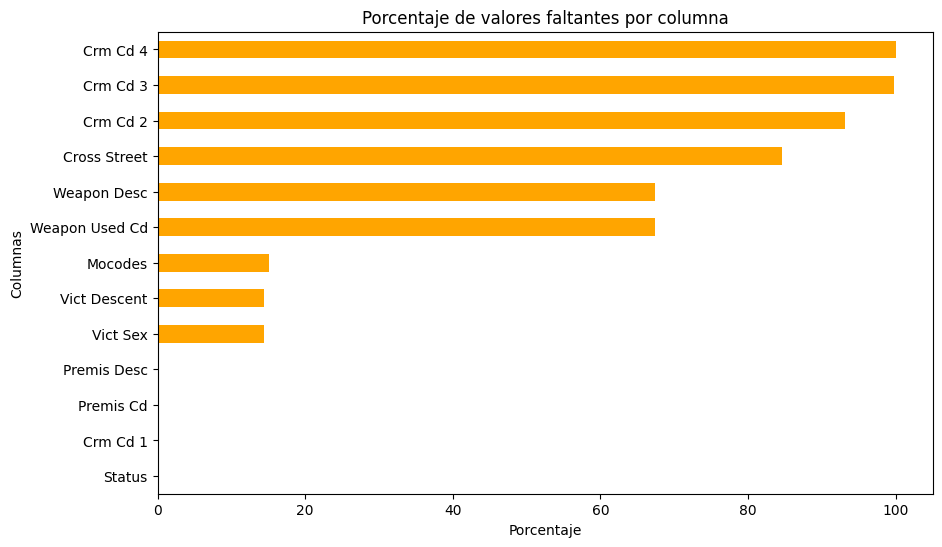

In [7]:
# Porcentaje de valores nulos por columna
missing_values = data.isnull().mean() * 100
print(missing_values[missing_values > 0].sort_values(ascending=False))

# Visualizar las columnas con valores nulos
plt.figure(figsize=(10, 6))
missing_values[missing_values > 0].sort_values().plot(kind='barh', color='orange')
plt.title("Porcentaje de valores faltantes por columna")
plt.xlabel("Porcentaje")
plt.ylabel("Columnas")
plt.show()


# Categorizacion y 

**Nota:** Lo que queremos es tener un dataframe con pocas categorias por variable, ya que tener muchas caeremos en el problema de la dimensionalidad, como queremos predecir el tipo de delito, lo mejor seria categorizalar y asignarlas a un tipo de delito, eso lo haremos teniendo en cuenta el codigo del PDF que nos brinda la pagina del FBI

In [8]:
# Calcular frecuencias
#frecuencias_cd1 = data['Crm Cd 1'].value_counts()
#frecuencias_cd2 = data['Crm Cd 2'].value_counts()

# Guardar en archivos de texto separados
#with open('frecuencias_crm_cd1.txt', 'w', encoding='utf-8') as f1:
#    f1.write("Frecuencias de 'Crm Cd 1'\n")
#    f1.write(frecuencias_cd1.to_string())

#with open('frecuencias_crm_cd2.txt', 'w', encoding='utf-8') as f2:
#    f2.write("Frecuencias de 'Crm Cd 2'\n")
#    f2.write(frecuencias_cd2.to_string())

In [9]:
frecuencias_cd3 = data['Weapon Used Cd'].value_counts()
with open('frecuencias_Weapon_Used_Cd.txt', 'w', encoding='utf-8') as f2:
    f2.write("Frecuencias de 'Weapon Used Cd'\n")
    f2.write(frecuencias_cd3.to_string())

In [10]:
frecuencias_cd4 = data['Crm Cd'].value_counts()
with open('frecuencias_Crm_Cd.txt', 'w', encoding='utf-8') as f2:
    f2.write("Frecuencias de Crm_Cd' Cd'\n")
    f2.write(frecuencias_cd4.to_string())

### Eliminamos:

Este proceso se omite por redundancia de información. Estas variables son más específicas del delito, pero no tiene sentido procesarlas si ya contamos con una que describe el delito principal.

In [11]:
# # Definir los grupos de códigos categorizados
# HOMICIDIO           = {110, 113}
# DELITO_SEXUAL       = {121, 122, 815, 820, 821}
# ROBO                = {210, 220}
# ASALTO_GRAVE        = {230, 231, 235, 236, 250, 251, 761, 926}
# ASALTO_SIMPLE       = {435, 436, 437, 622, 623, 624, 625, 626, 627}
# BURGLARY            = {310, 320}
# BTFV                = {330, 331, 410, 420, 421}
# GTA                 = {433, 510, 520}
# HURTO_PERSONAL      = {350, 351, 352, 353}
# HURTOS_VARIOS       = {
#     341, 343, 345,
#     440, 441, 442, 443, 444, 445,
#     470, 471, 472, 473, 474, 475,
#     480, 485, 487, 491
# }
# VANDALISMO          = {740, 741, 742, 743, 744, 745, 753, 760, 762}
# AMENAZAS_INTIM      = {930, 928, 880, 882}
# NARCOTICOS          = {901, 850, 812}
# VIOL_ORDEN          = {886, 922, 920, 921}
# DELITO_TRANSITO     = {956, 890}
# PERSONA_MISSING     = {910, 860, 980, 990, 998, 999}
# POSESION_ARMA       = {651, 652, 653, 660, 670, 666, 668}
# CONDUCTA_DESORDEN   = {888, 900}

# # Función de categorización
# def categorizar(cd):
#     if pd.isna(cd):
#         return 'DESCONOCIDO'
#     try:
#         c = int(cd)
#     except ValueError:
#         return 'DESCONOCIDO'

#     if   c in HOMICIDIO:           return 'HOMICIDIO'
#     elif c in DELITO_SEXUAL:       return 'DELITO_SEXUAL'
#     elif c in ROBO:                return 'ROBO'
#     elif c in ASALTO_GRAVE:        return 'ASALTO_GRAVE'
#     elif c in ASALTO_SIMPLE:       return 'ASALTO_SIMPLE'
#     elif c in BURGLARY:            return 'BURGLARY'
#     elif c in BTFV:                return 'BTFV'
#     elif c in GTA:                 return 'GTA'
#     elif c in HURTO_PERSONAL:      return 'HURTO_PERSONAL'
#     elif c in HURTOS_VARIOS:       return 'HURTOS_VARIOS'
#     elif c in VANDALISMO:          return 'VANDALISMO'
#     elif c in AMENAZAS_INTIM:      return 'AMENAZAS_INTIM'
#     elif c in NARCOTICOS:          return 'NARCOTICOS'
#     elif c in VIOL_ORDEN:          return 'VIOL_ORDEN'
#     elif c in DELITO_TRANSITO:     return 'DELITO_TRANSITO'
#     elif c in PERSONA_MISSING:     return 'PERSONA_MISSING'
#     elif c in POSESION_ARMA:       return 'POSESION_ARMA'
#     elif c in CONDUCTA_DESORDEN:   return 'CONDUCTA_DESORDEN'
#     else:                          return 'OTRAS_INFRACCIONES'

# # Aplicar categorización a ambas columnas de código de delito
# data['delito_cd1'] = data['Crm Cd 1'].apply(categorizar)
# data['delito_cd2'] = data['Crm Cd 2'].apply(categorizar)

# # Mostrar frecuencias para ver distribución
# print('Frecuencias CD1:\n', data['delito_cd1'].value_counts(), '\n')
# print('Frecuencias CD2:\n', data['delito_cd2'].value_counts())

# # One-hot encoding
# dummies_cd1 = pd.get_dummies(data['delito_cd1'], prefix='cd1')
# dummies_cd2 = pd.get_dummies(data['delito_cd2'], prefix='cd2')

# # Concatenar dummies
# X = pd.concat([dummies_cd1, dummies_cd2], axis=1)

# # Guardar diccionarios de mapeo
# mapa_cd1 = {str(c): categorizar(c) for c in data['Crm Cd 1'].dropna().unique()}
# mapa_cd2 = {str(c): categorizar(c) for c in data['Crm Cd 2'].dropna().unique()}

# with open('mapa_delitos_cd1.json', 'w', encoding='utf-8') as f:
#     json.dump(mapa_cd1, f, indent=2, ensure_ascii=False)

# with open('mapa_delitos_cd2.json', 'w', encoding='utf-8') as f:
#     json.dump(mapa_cd2, f, indent=2, ensure_ascii=False)


### Crm Cd (ya no se usa)

In [12]:
# # Diccionario de agrupación optimizada por tipo de delito
# CAT = {
#     'HOMICIDIO':        {110, 113},
#     'DELITO_SEXUAL':    {121, 122, 815, 820, 821},
#     'ROBO':             {210, 220},
#     'ASALTO_GRAVE':     {230, 231, 235, 236, 250, 251, 761, 926},
#     'ASALTO_SIMPLE':    {435, 436, 437, 622, 623, 624, 625, 626, 627},
#     'BURGLARY':         {310, 320},
#     'BTFV':             {330, 331, 410, 420, 421},
#     'GTA':              {510, 520, 433},
#     'HURTO_PERSONAL':   {350, 351, 352, 353},
#     'HURTOS_VARIOS': {
#         341, 343, 345,
#         440, 441, 442, 443, 444, 445,
#         470, 471, 472, 473, 474, 475,
#         480, 485, 487, 491
#     },
#     'VANDALISMO':       {740, 741, 742, 743, 744, 745, 753, 760, 762},
#     'AMENAZAS_INTIM':   {930, 928, 880, 882},
#     'NARCOTICOS':       {901, 850},
#     'VIOL_ORDEN':       {886, 922},
#     'DELITO_TRANSITO':  {956, 890},
#     'PERSONA_MISS':     {910},
#     'POSESION_ARMA':    {651, 652, 653, 660},
#     'CONDUCTA_DESORDEN': {888, 900}
# }

# # Función para asignar categoría a partir del código
# def categorizar_opt(cd):
#     if pd.isna(cd):
#         return 'DESCONOCIDO'
#     try:
#         cd = int(cd)
#     except ValueError:
#         return 'DESCONOCIDO'

#     for nombre, codigos in CAT.items():
#         if cd in codigos:
#             return nombre
#     return 'OTRAS_INFRACCIONES'

# # Aplicar categorización al DataFrame
# data['delito_cat'] = data['Crm Cd'].apply(categorizar_opt)

# # Verificar frecuencias por categoría
# print('\nFrecuencia tras la nueva agrupación:')
# print(data['delito_cat'].value_counts(dropna=False))

# mapa_delito_cat = {str(cd): categorizar_opt(cd) for cd in data['Crm Cd'].dropna().unique()}
# with open('mapa_delito_cat.json', 'w', encoding='utf-8') as f:
#     json.dump(mapa_delito_cat, f, indent=2, ensure_ascii=False)


# One-hot encoding si se requiere
#dummies = pd.get_dummies(data['delito_cat'], prefix='delito')

# Crear diccionario de mapeo para trazabilidad
#mapping = {str(c): categorizar_opt(c) for c in data['Crm Cd'].dropna().unique()}

#with open('mapa_delitos_crm_cd_opt.json', 'w', encoding='utf-8') as f:
#    json.dump(mapping, f, indent=2, ensure_ascii=False)




### Weapon Used Cd

 Realizamos lo mismo pero para las armas

In [13]:
# Función de mapeo a subcategorías de armas
def arma_sub(codigo):
    if pd.isna(codigo):
        return 'ARMA_DESCONOCIDA'
    try:
        cod = int(codigo)
    except ValueError:
        return 'ARMA_DESCONOCIDA'

    if   101 <= cod <= 109: return 'PISTOLA'
    elif 111 <= cod <= 129: return 'RIFLE_ESCOPETA'
    elif 200 <= cod <= 219: return 'CUCHILLO_NAVAJA'
    elif 220 <= cod <= 229: return 'ARMA_CORTANTE_OTRA'
    elif 300 <= cod <= 319: return 'GOLPE_CONTUNDENTE'
    elif 320 <= cod <= 399: return 'OBJETO_CONTUNDENTE_OTRO'
    elif cod == 400:        return 'FUERZA_CORPORAL'
    elif 501 <= cod <= 509: return 'SUSTANCIA_QUIMICA'
    elif 510 <= cod <= 519: return 'ESTUPEFACIENTE'
    elif 520 <= cod <= 529: return 'ARMA_INCENDIARIA'
    elif 530 <= cod <= 539: return 'ARMA_IMPROVISADA'
    elif 590 <= cod <= 599: return 'ARMA_OTRA'
    else:                   return 'ARMA_DESCONOCIDA'

# Aplicar la función al DataFrame
data['arma_cat'] = data['Weapon Used Cd'].apply(arma_sub)

# Visualizar distribución de subcategorías
print(data['arma_cat'].value_counts())

# One-hot encoding de las subcategorías
dummies_armas_cat = pd.get_dummies(data['arma_cat'], prefix='arma_cat')

# Guardar el mapeo para trazabilidad o inferencia futura
mapa_armas_sub = {str(c): arma_sub(c) for c in data['Weapon Used Cd'].dropna().unique()}
with open('mapa_armas_sub.json', 'w', encoding='utf-8') as f:
    json.dump(mapa_armas_sub, f, indent=2, ensure_ascii=False)

arma_cat
ARMA_DESCONOCIDA      714187
FUERZA_CORPORAL       174761
PISTOLA                37033
ESTUPEFACIENTE         29263
CUCHILLO_NAVAJA        25662
GOLPE_CONTUNDENTE      17877
RIFLE_ESCOPETA          3552
SUSTANCIA_QUIMICA       1413
ARMA_CORTANTE_OTRA      1241
Name: count, dtype: int64


In [14]:
missing_values = data.isnull().mean() * 100
print(missing_values[missing_values > 0].sort_values(ascending=False))

Crm Cd 4          99.993632
Crm Cd 3          99.769749
Crm Cd 2          93.118532
Cross Street      84.653066
Weapon Desc       67.437753
Weapon Used Cd    67.437753
Mocodes           15.086732
Vict Descent      14.393789
Vict Sex          14.392595
Premis Desc        0.058508
Premis Cd          0.001592
Crm Cd 1           0.001095
Status             0.000100
dtype: float64


#   Análisis Univariado

Variables Categóricas.

Observamos la distribucion de las variables categoricas mas relevantes

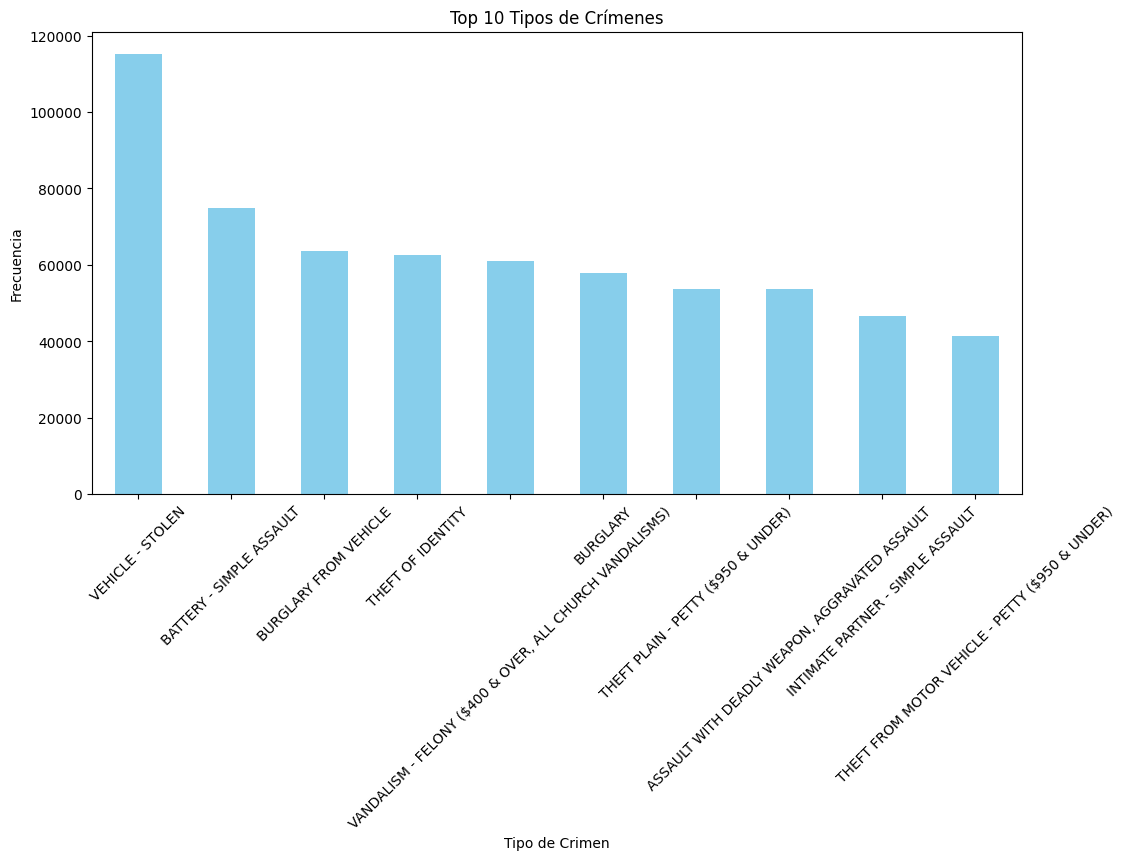

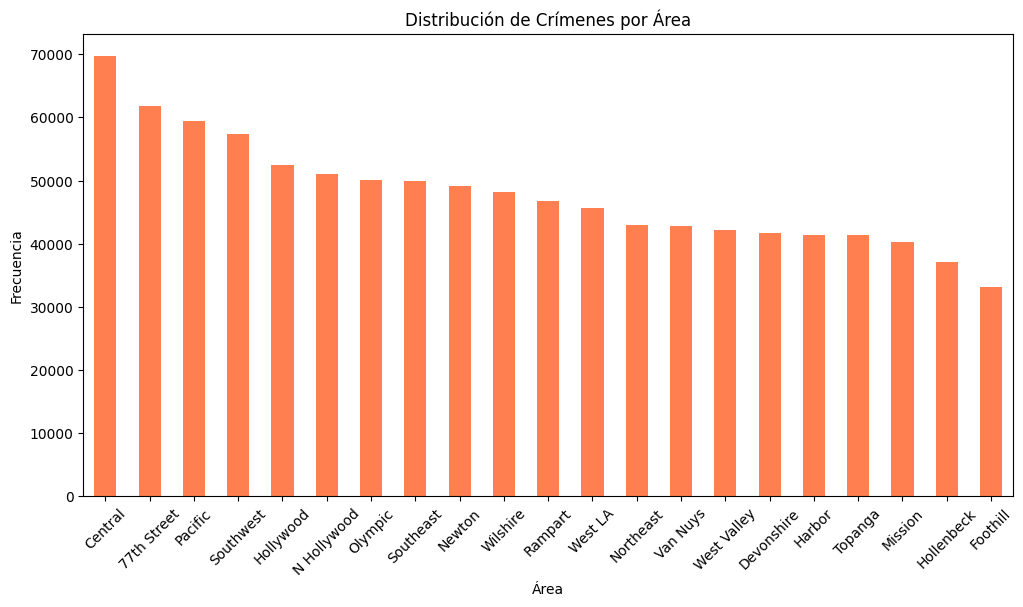

In [15]:
# Frecuencia de crímenes por tipo
plt.figure(figsize=(12, 6))
data['Crm Cd Desc'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title("Top 10 Tipos de Crímenes")
plt.ylabel("Frecuencia")
plt.xlabel("Tipo de Crimen")
plt.xticks(rotation=45)
plt.show()

# Frecuencia de crímenes por área
plt.figure(figsize=(12, 6))
data['AREA NAME'].value_counts().plot(kind='bar', color='coral')
plt.title("Distribución de Crímenes por Área")
plt.ylabel("Frecuencia")
plt.xlabel("Área")
plt.xticks(rotation=45)
plt.show()


Variables Numéricas.

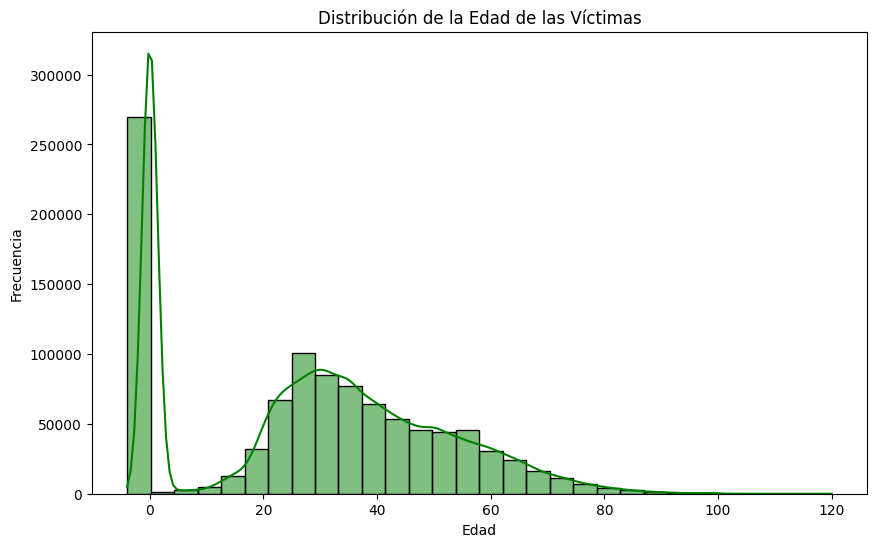

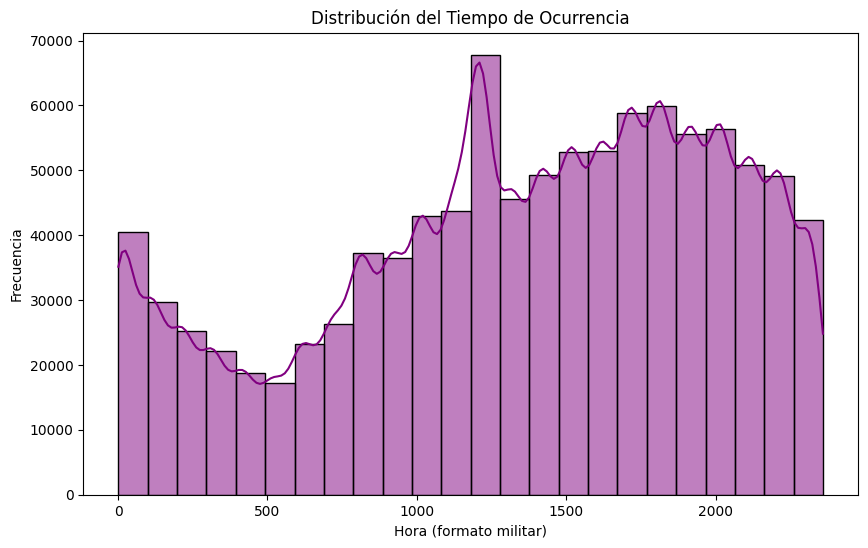

In [16]:
# Distribución de la edad de las víctimas
plt.figure(figsize=(10, 6))
sns.histplot(data['Vict Age'], kde=True, bins=30, color='green')
plt.title("Distribución de la Edad de las Víctimas")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

# Distribución del tiempo de ocurrencia
plt.figure(figsize=(10, 6))
sns.histplot(data['TIME OCC'], kde=True, bins=24, color='purple')
plt.title("Distribución del Tiempo de Ocurrencia")
plt.xlabel("Hora (formato militar)")
plt.ylabel("Frecuencia")
plt.show()


#   Análisis Bivariado

Relación entre Crm Cd Desc y Vict Sex.


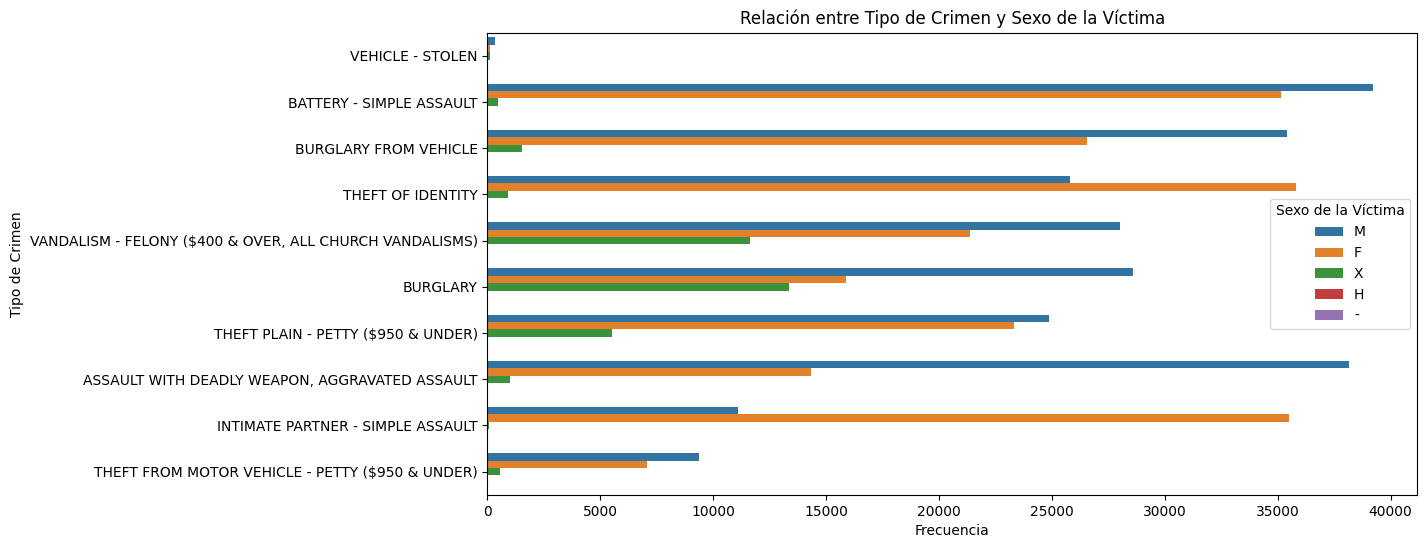

In [17]:
# Relación entre tipo de crimen y sexo de la víctima
plt.figure(figsize=(12, 6))
sns.countplot(data=data, y='Crm Cd Desc', hue='Vict Sex', order=data['Crm Cd Desc'].value_counts().iloc[:10].index)
plt.title("Relación entre Tipo de Crimen y Sexo de la Víctima")
plt.ylabel("Tipo de Crimen")
plt.xlabel("Frecuencia")
plt.legend(title="Sexo de la Víctima")
plt.show()


Relación entre TIME OCC y Crm Cd Desc.

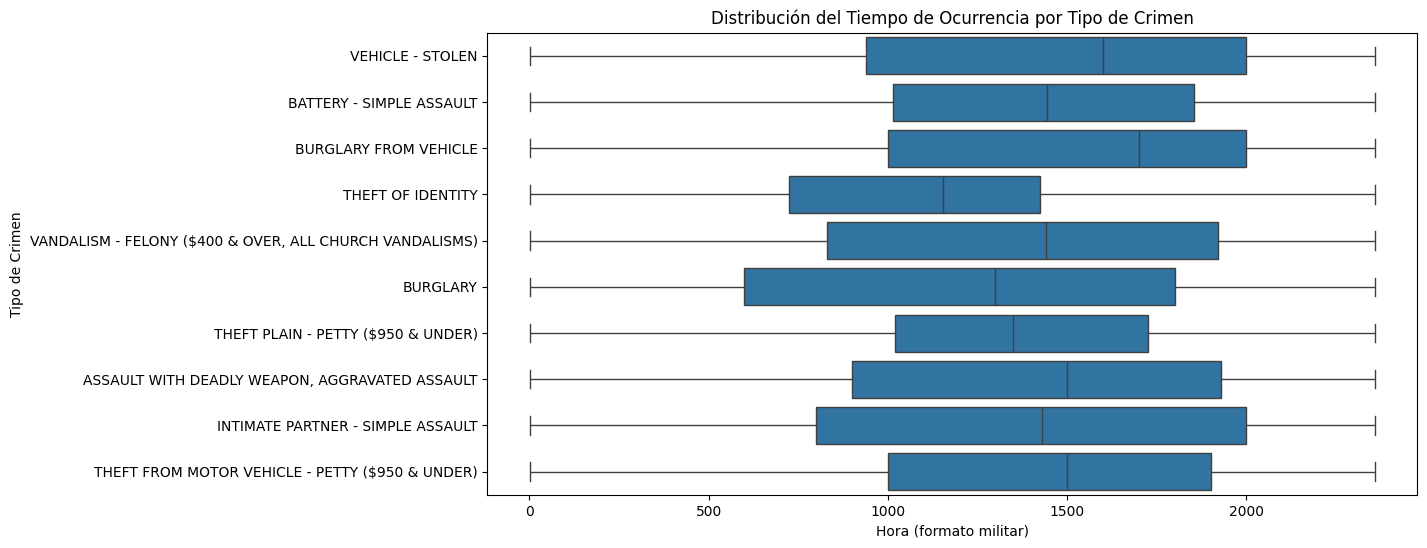

In [18]:
# Boxplot para crímenes según el tiempo
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='TIME OCC', y='Crm Cd Desc', order=data['Crm Cd Desc'].value_counts().iloc[:10].index)
plt.title("Distribución del Tiempo de Ocurrencia por Tipo de Crimen")
plt.xlabel("Hora (formato militar)")
plt.ylabel("Tipo de Crimen")
# plt.xticks(rotation=45)
plt.show()


#   Análisis Geográfico
Mapa interactivo de la ubicación de los crímenes usando LAT y LON.

In [19]:
# Selección de una muestra para visualización (opcional, si el dataset es muy grande)
sample_data = data.sample(5000, random_state=42)

# Mapa interactivo con Plotly
fig = px.scatter_mapbox(
    sample_data,
    lat="LAT",
    lon="LON",
    color="Crm Cd Desc",
    hover_name="AREA NAME",
    title="Mapa de Crímenes en Los Ángeles",
    mapbox_style="carto-positron",
    zoom=10,
    height=600
)
fig.show()


/tmp/ipykernel_7843/460619843.py:5: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(


In [20]:
data['Premis Desc'].unique()

array(['SINGLE FAMILY DWELLING', 'SIDEWALK', 'STREET', 'ALLEY',
       'MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)',
       'YARD (RESIDENTIAL/BUSINESS)', 'PARKING LOT', 'OTHER BUSINESS',
       'GARAGE/CARPORT', 'TRANSPORTATION FACILITY (AIRPORT)',
       'RESTAURANT/FAST FOOD', 'PARK/PLAYGROUND',
       'VEHICLE, PASSENGER/TRUCK', 'HOTEL', 'OTHER RESIDENCE',
       'BAR/SPORTS BAR (OPEN DAY & NIGHT)', 'GAS STATION',
       'PARKING UNDERGROUND/BUILDING',
       'CHURCH/CHAPEL (CHANGED 03-03 FROM CHURCH/TEMPLE)',
       'CELL PHONE STORE', 'SHOPPING MALL (COMMON AREA)',
       'PORCH, RESIDENTIAL', 'DAM/RESERVOIR', 'OTHER/OUTSIDE', 'DRIVEWAY',
       'TRADE SCHOOL (MEDICAL-TECHNICAL-BUSINESS)*', 'HEALTH SPA/GYM',
       'PATIO*', 'MARKET', 'DEPARTMENT STORE', 'CONDOMINIUM/TOWNHOUSE',
       "SEX ORIENTED/BOOK STORE/STRIP CLUB/GENTLEMAN'S CLUB",
       'MTA - ORANGE LINE - NORTH HOLLYWOOD', 'OTHER PREMISE',
       'STORAGE SHED', 'HIGH SCHOOL', 'CLOTHING STORE',
       'JUNIOR HIGH S

### Premis Desc

In [21]:
# Contar frecuencia de las categorías en Premis Desc
frec_premis_desc = data['Premis Desc'].value_counts()

# Mostrar las 30 categorías más comunes
print(frec_premis_desc.head(30))


Premis Desc
STREET                                          261283
SINGLE FAMILY DWELLING                          163654
MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)    119011
PARKING LOT                                      69147
OTHER BUSINESS                                   47647
SIDEWALK                                         40861
VEHICLE, PASSENGER/TRUCK                         29302
GARAGE/CARPORT                                   19362
DRIVEWAY                                         16082
DEPARTMENT STORE                                 14433
RESTAURANT/FAST FOOD                             12312
PARKING UNDERGROUND/BUILDING                      8228
OTHER PREMISE                                     8038
MARKET                                            7884
OTHER RESIDENCE                                   7558
ALLEY                                             7066
PARK/PLAYGROUND                                   6666
CLOTHING STORE                                    620

Revisamos si hay registros duplicados

In [22]:
# Contar frecuencia de las categorías en Premis Desc
frec_premis_desc = data['Premis Desc'].value_counts()

# Mostrar las 1000 categorías más comunes
top_200_premis = frec_premis_desc.head(1000)
print(top_200_premis)

# Guardar en un archivo si prefieres enviármelo directamente
top_200_premis.to_csv('top_200_premis_desc.csv', index=True)


Premis Desc
STREET                                          261283
SINGLE FAMILY DWELLING                          163654
MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)    119011
PARKING LOT                                      69147
OTHER BUSINESS                                   47647
                                                 ...  
MTA - SILVER LINE - DOWNTOWN STREET STOPS            2
MTA - SILVER LINE - LAC/USC MEDICAL CENTER           2
DEPT OF DEFENSE FACILITY                             2
HORSE RACING/SANTA ANITA PARK*                       2
TRAM/STREETCAR(BOXLIKE WAG ON RAILS)*                1
Name: count, Length: 306, dtype: int64


In [23]:
# Diccionario de clasificación compacto
clasificacion = {
    # Residencial
    'SINGLE FAMILY DWELLING': 'Residencial',
    'MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)': 'Residencial',
    'GARAGE/CARPORT': 'Residencial',
    'DRIVEWAY': 'Residencial',
    'OTHER RESIDENCE': 'Residencial',
    'YARD (RESIDENTIAL/BUSINESS)': 'Residencial',
    'PORCH, RESIDENTIAL': 'Residencial',
    'CONDOMINIUM/TOWNHOUSE': 'Residencial',
    'STORAGE SHED': 'Residencial',
    'ABANDONED BUILDING ABANDONED HOUSE': 'Residencial',
    'GROUP HOME': 'Residencial',
    'MOBILE HOME/TRAILERS/CONSTRUCTION TRAILERS/RV\'S/MOTORHOME': 'Residencial',
    'TRANSITIONAL HOUSING/HALFWAY HOUSE': 'Residencial',
    'PATIO*': 'Residencial',
    'SINGLE RESIDENCE OCCUPANCY (SRO\'S) LOCATIONS': 'Residencial',
    'PROJECT/TENEMENT/PUBLIC HOUSING': 'Residencial',
    'BALCONY*': 'Residencial',
    'APARTMENT/CONDO COMMON LAUNDRY ROOM': 'Residencial',
    'FRAT HOUSE/SORORITY/DORMITORY': 'Residencial',
    'SHORT-TERM VACATION RENTAL': 'Residencial',
    'TOOL SHED*': 'Residencial',
    'FOSTER HOME BOYS OR GIRLS*': 'Residencial',

    # Comercial
    'OTHER BUSINESS': 'Comercial',
    'DEPARTMENT STORE': 'Comercial',
    'RESTAURANT/FAST FOOD': 'Comercial',
    'MARKET': 'Comercial',
    'CLOTHING STORE': 'Comercial',
    'GAS STATION': 'Comercial',
    'HOTEL': 'Comercial',
    'OTHER STORE': 'Comercial',
    'DRUG STORE': 'Comercial',
    'MINI-MART': 'Comercial',
    'BANK': 'Comercial',
    'PUBLIC STORAGE': 'Comercial',
    'OFFICE BUILDING/OFFICE': 'Comercial',
    'LIQUOR STORE': 'Comercial',
    'AUTOMATED TELLER MACHINE (ATM)': 'Comercial',
    'MOTEL': 'Comercial',
    'HEALTH SPA/GYM': 'Comercial',
    'WAREHOUSE': 'Comercial',
    'CONSTRUCTION SITE': 'Comercial',
    'SHOPPING MALL (COMMON AREA)': 'Comercial',
    'LAUNDROMAT': 'Comercial',
    'CELL PHONE STORE': 'Comercial',
    'COFFEE SHOP (STARBUCKS, COFFEE BEAN, PEET\'S, ETC.)': 'Comercial',
    'DIY CENTER (LOWE\'S, HOME DEPOT, OSH, CONTRACTORS WAREHOUSE)': 'Comercial',
    'DISCOUNT STORE (99 CENT, DOLLAR, ETC.)': 'Comercial',
    'AUTO REPAIR SHOP': 'Comercial',
    'THE GROVE': 'Comercial',
    'BEAUTY/BARBER SHOP': 'Comercial',
    'AUTO SUPPLY STORE*': 'Comercial',
    'CAR WASH': 'Comercial',
    'MEMBERSHIP STORE (COSTCO, SAM\'S CLUB)*': 'Comercial',
    'BEAUTY SUPPLY STORE': 'Comercial',
    'TOBACCO SHOP': 'Comercial',
    'PHARMACY INSIDE STORE OR SUPERMARKET*': 'Comercial',
    'HARDWARE/BUILDING SUPPLY': 'Comercial',
    'THE BEVERLY CONNECTION': 'Comercial',
    'AUTO DEALERSHIP (CHEVY, FORD, BMW, MERCEDES, ETC.)': 'Comercial',
    'JEWELRY STORE': 'Comercial',
    'THE BEVERLY CENTER': 'Comercial',
    'GUN/SPORTING GOODS': 'Comercial',
    'DELIVERY SERVICE (FED EX, UPS, COURIERS, COURIER SERVICE)*': 'Comercial',
    'NAIL SALON': 'Comercial',
    'CHECK CASHING*': 'Comercial',
    'AUTO SALES LOT': 'Comercial',
    'HIGH-RISE BUILDING': 'Comercial',
    'ELECTRONICS STORE (IE: RADIO SHACK, ETC.)': 'Comercial',
    'TOW YARD*': 'Comercial',
    'NURSERY/FLOWER SHOP': 'Comercial',
    'RECYCLING CENTER': 'Comercial',
    'PET STORE': 'Comercial',
    'MASSAGE PARLOR': 'Comercial',
    'DRIVE THRU*': 'Comercial',
    'CLEANER/LAUNDROMAT': 'Comercial',
    'MANUFACTURING COMPANY': 'Comercial',
    'SWAP MEET': 'Comercial',
    'FURNITURE STORE': 'Comercial',
    'TELECOMMUNICATION FACILITY/LOCATION': 'Comercial',
    'PAWN SHOP': 'Comercial',
    'CREDIT UNION': 'Comercial',
    'TATTOO PARLOR*': 'Comercial',
    'BOOK STORE': 'Comercial',
    'EQUIPMENT RENTAL': 'Comercial',
    'FACTORY': 'Comercial',
    'CATERING/ICE CREAM TRUCK': 'Comercial',
    'TV/RADIO/APPLIANCE': 'Comercial',
    'RECORD-CD MUSIC/COMPUTER GAME STORE': 'Comercial',
    'BANKING INSIDE MARKET-STORE *': 'Comercial',
    'GARMENT MANUFACTURER': 'Comercial',
    'OPTICAL OFFICE INSIDE STORE OR SUPERMARKET*': 'Comercial',
    'ESCALATOR*': 'Comercial',
    'VIDEO RENTAL STORE': 'Comercial',
    'BANK DROP BOX/MONEY DROP-OUTSIDE OF BANK*': 'Comercial',
    'SURPLUS SURVIVAL STORE': 'Comercial',
    'COMPUTER SERVICES/REPAIRS/SALES': 'Comercial',
    'DRIVE THRU BANKING (WINDOW)*': 'Comercial',

    # Transporte
    'PARKING LOT': 'Transporte',
    'VEHICLE, PASSENGER/TRUCK': 'Transporte',
    'PARKING UNDERGROUND/BUILDING': 'Transporte',
    'TRANSPORTATION FACILITY (AIRPORT)': 'Transporte',
    'MTA BUS': 'Transporte',
    'BUS STOP': 'Transporte',
    'LA UNION STATION (NOT LINE SPECIFIC)': 'Transporte',
    'MTA PROPERTY OR PARKING LOT': 'Transporte',
    'MTA - RED LINE - [VARIAS ESTACIONES]': 'Transporte',
    'MTA - EXPO LINE - [VARIAS ESTACIONES]': 'Transporte',
    'MTA - BLUE LINE - [VARIAS ESTACIONES]': 'Transporte',
    'MTA - PURPLE LINE - [VARIAS ESTACIONES]': 'Transporte',
    'MTA - GREEN LINE - [VARIAS ESTACIONES]': 'Transporte',
    'MTA - GOLD LINE - [VARIAS ESTACIONES]': 'Transporte',
    'METROLINK TRAIN': 'Transporte',
    'VEHICLE STORAGE LOT (CARS, TRUCKS, RV\'S, BOATS, TRAILERS, ETC.)': 'Transporte',
    'MUNICIPAL BUS LINE INCLUDES LADOT/DASH': 'Transporte',
    'TAXI': 'Transporte',
    'FREEWAY': 'Transporte',
    'TRAIN TRACKS': 'Transporte',
    'BUS-CHARTER/PRIVATE': 'Transporte',
    'GREYHOUND OR INTERSTATE BUS': 'Transporte',
    'OTHER RR TRAIN (UNION PAC, SANTA FE ETC)': 'Transporte',
    'AIRCRAFT': 'Transporte',
    'AMTRAK TRAIN': 'Transporte',
    'TRAIN DEPOT/TERMINAL, OTHER THAN MTA': 'Transporte',
    'BUS DEPOT/TERMINAL, OTHER THAN MTA': 'Transporte',
    'TRUCK, COMMERCIAL': 'Transporte',
    'OTHER INTERSTATE, CHARTER BUS': 'Transporte',
    'TUNNEL': 'Transporte',
    'VALET': 'Transporte',
    'SLIPS/DOCK/MARINA/BOAT': 'Transporte',
    'MTA - SILVER LINE - [VARIAS ESTACIONES]': 'Transporte',

    # Educación
    'HIGH SCHOOL': 'Educación',
    'ELEMENTARY SCHOOL': 'Educación',
    'JUNIOR HIGH SCHOOL': 'Educación',
    'COLLEGE/JUNIOR COLLEGE/UNIVERSITY': 'Educación',
    'SPECIALTY SCHOOL/OTHER': 'Educación',
    'PRIVATE SCHOOL/PRESCHOOL': 'Educación',
    'TRADE SCHOOL (MEDICAL-TECHNICAL-BUSINESS)*': 'Educación',
    'DAY CARE/CHILDREN*': 'Educación',

    # Salud
    'HOSPITAL': 'Salud',
    'NURSING/CONVALESCENT/RETIREMENT HOME': 'Salud',
    'MEDICAL/DENTAL OFFICES': 'Salud',
    'MEDICAL MARIJUANA FACILITIES/BUSINESSES': 'Salud',
    'VISION CARE FACILITY*': 'Salud',
    'VETERINARIAN/ANIMAL HOSPITAL': 'Salud',
    'HOSPICE': 'Salud',
    'METHADONE CLINIC': 'Salud',
    'ABORTION CLINIC/ABORTION FACILITY*': 'Salud',

    # Gobierno
    'POLICE FACILITY': 'Gobierno',
    'GOVERNMENT FACILITY (FEDERAL, STATE, COUNTY & CITY)': 'Gobierno',
    'POST OFFICE': 'Gobierno',
    'FIRE STATION': 'Gobierno',
    'DETENTION/JAIL FACILITY': 'Gobierno',
    'DEPT OF DEFENSE FACILITY': 'Gobierno',

    # Entretenimiento
    'BAR/COCKTAIL/NIGHTCLUB': 'Entretenimiento',
    'NIGHT CLUB (OPEN EVENINGS ONLY)': 'Entretenimiento',
    'BAR/SPORTS BAR (OPEN DAY & NIGHT)': 'Entretenimiento',
    'DODGER STADIUM': 'Entretenimiento',
    'THEATRE/MOVIE': 'Entretenimiento',
    'STUDIO (FILM/PHOTOGRAPHIC/MUSIC)': 'Entretenimiento',
    'ENTERTAINMENT/COMEDY CLUB (OTHER)': 'Entretenimiento',
    'SPORTS ARENA': 'Entretenimiento',
    'SPORTS VENUE, OTHER': 'Entretenimiento',
    'COLISEUM': 'Entretenimiento',
    'GOLF COURSE*': 'Entretenimiento',
    'POOL-PUBLIC/OUTDOOR OR INDOOR*': 'Entretenimiento',
    'BOWLING ALLEY*': 'Entretenimiento',
    'ARCADE, GAME ROOM/VIDEO GAMES (EXAMPLE CHUCKIE CHEESE)*': 'Entretenimiento',
    'SKATEBOARD FACILITY/SKATEBOARD PARK*': 'Entretenimiento',
    'BASKETBALL COURTS': 'Entretenimiento',
    'AMUSEMENT PARK*': 'Entretenimiento',
    'SKATING RINK*': 'Entretenimiento',
    'HANDBALL COURTS': 'Entretenimiento',
    'HORSE RACING/SANTA ANITA PARK*': 'Entretenimiento',
    'MUSCLE BEACH': 'Entretenimiento',
    'SEX ORIENTED/BOOK STORE/STRIP CLUB/GENTLEMAN\'S CLUB': 'Entretenimiento',

    # Religioso
    'CHURCH/CHAPEL': 'Religioso',
    'SYNAGOGUE/TEMPLE': 'Religioso',
    'OTHER PLACE OF WORSHIP': 'Religioso',
    'MOSQUE*': 'Religioso',

    # Vía Pública
    'STREET': 'Vía Pública',
    'SIDEWALK': 'Vía Pública',
    'ALLEY': 'Vía Pública',
    'OTHER/OUTSIDE': 'Vía Pública',
    'UNDERPASS/BRIDGE*': 'Vía Pública',
    'RIVER BED*': 'Vía Pública',
    'PEDESTRIAN OVERCROSSING': 'Vía Pública',

    # Instalaciones Públicas
    'PARK/PLAYGROUND': 'Instalaciones Públicas',
    'BEACH': 'Instalaciones Públicas',
    'MISSIONS/SHELTERS': 'Instalaciones Públicas',
    'LIBRARY': 'Instalaciones Públicas',
    'PUBLIC RESTROOM (INDOORS-INSIDE)': 'Instalaciones Públicas',
    'PUBLIC RESTROOM/OUTSIDE*': 'Instalaciones Públicas',
    'CONVENTION CENTER': 'Instalaciones Públicas',
    'MUSEUM': 'Instalaciones Públicas',
    'CEMETERY*': 'Instalaciones Públicas',
    'CULTURAL SIGNIFICANCE/MONUMENT': 'Instalaciones Públicas',
    'MASS GATHERING LOCATION': 'Instalaciones Públicas',
}


In [24]:
# Aplicar clasificación al dataset
data['Premis Desc Cat'] = (
    data['Premis Desc']
    .map(clasificacion)
    .fillna('Otros')  # Etiqueta por defecto para casos no mapeados
)

# One-hot encoding sobre la categoría clasificada
dummies_lugar_delito = pd.get_dummies(
    data['Premis Desc Cat'],
    prefix='premis'
)

# Guardar el mapeo para trazabilidad/inferencia futura
with open('mapa_premis_desc.json', 'w', encoding='utf-8') as f:
    json.dump(clasificacion, f, indent=2, ensure_ascii=False)

# Mostrar columnas generadas por el one-hot encoding
print("Columnas one-hot de 'Premis Desc Clasificado':")
print(dummies_lugar_delito.columns.tolist())


Columnas one-hot de 'Premis Desc Clasificado':
['premis_Comercial', 'premis_Educación', 'premis_Entretenimiento', 'premis_Gobierno', 'premis_Instalaciones Públicas', 'premis_Otros', 'premis_Religioso', 'premis_Residencial', 'premis_Salud', 'premis_Transporte', 'premis_Vía Pública']


In [25]:
data['Premis Desc Cat'].value_counts()

Premis Desc Cat
Residencial               346091
Vía Pública               313131
Comercial                 156297
Transporte                120553
Otros                      33305
Instalaciones Públicas     10364
Educación                   9946
Entretenimiento             7132
Salud                       5281
Gobierno                    2576
Religioso                    313
Name: count, dtype: int64

In [26]:
# # data['Crm Cd Desc'].value_counts()

# # Contar frecuencia de las categorías en Crm Cd Desc
# frec_crm_cd_desc = data['Crm Cd Desc'].value_counts()

# # Mostrar las 1000 categorías más comunes
# top_1000_crm_cd_desc = frec_crm_cd_desc.head(1000)
# print(top_1000_crm_cd_desc)

# # Guardar en un archivo si prefieres enviármelo directamente
# top_1000_crm_cd_desc.to_csv('top_1000_crm_cd_desc.csv', index=True)

### Variable predictoria delitos lo clasificamos tambien

In [27]:
clasificacion = {
    # Robo y Hurto
    'THEFT PLAIN - PETTY ($950 & UNDER)': 'Robo y Hurto',
    'THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)': 'Robo y Hurto',
    'THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER)': 'Robo y Hurto',
    'THEFT-GRAND ($950.01 & OVER) EXCEPT GUNS, FOWL, LIVESTOCK, PROD': 'Robo y Hurto',
    'SHOPLIFTING - PETTY THEFT ($950 & UNDER)': 'Robo y Hurto',
    'BIKE - STOLEN': 'Robo y Hurto',
    'BUNCO, GRAND THEFT': 'Robo y Hurto',
    'SHOPLIFTING-GRAND THEFT ($950.01 & OVER)': 'Robo y Hurto',
    'THEFT, PERSON': 'Robo y Hurto',
    'PICKPOCKET': 'Robo y Hurto',
    'BUNCO, PETTY THEFT': 'Robo y Hurto',
    'THEFT PLAIN - ATTEMPT': 'Robo y Hurto',
    'DEFRAUDING INNKEEPER/THEFT OF SERVICES, $950 & UNDER': 'Robo y Hurto',
    'DEFRAUDING INNKEEPER/THEFT OF SERVICES, OVER $950.01': 'Robo y Hurto',
    'PURSE SNATCHING': 'Robo y Hurto',
    'THEFT FROM PERSON - ATTEMPT': 'Robo y Hurto',
    'DRUNK ROLL': 'Robo y Hurto',
    'DISHONEST EMPLOYEE - GRAND THEFT': 'Robo y Hurto',
    'DISHONEST EMPLOYEE - PETTY THEFT': 'Robo y Hurto',
    'TILL TAP - PETTY ($950 & UNDER)': 'Robo y Hurto',
    'TILL TAP - GRAND THEFT ($950.01 & OVER)': 'Robo y Hurto',
    'THEFT, COIN MACHINE - PETTY ($950 & UNDER)': 'Robo y Hurto',
    'THEFT, COIN MACHINE - GRAND ($950.01 & OVER)': 'Robo y Hurto',
    'GRAND THEFT / AUTO REPAIR': 'Robo y Hurto',
    'PETTY THEFT - AUTO REPAIR': 'Robo y Hurto',
    'PICKPOCKET, ATTEMPT': 'Robo y Hurto',
    'BIKE - ATTEMPTED STOLEN': 'Robo y Hurto',
    'DRUNK ROLL - ATTEMPT': 'Robo y Hurto',
    'DISHONEST EMPLOYEE ATTEMPTED THEFT': 'Robo y Hurto',
    'THEFT, COIN MACHINE - ATTEMPT': 'Robo y Hurto',
    'PURSE SNATCHING - ATTEMPT': 'Robo y Hurto',
    'SHOPLIFTING - ATTEMPT': 'Robo y Hurto',

    # Allanamiento y Robo en Propiedad
    'BURGLARY': 'Allanamiento y Robo en Propiedad',
    'BURGLARY FROM VEHICLE': 'Allanamiento y Robo en Propiedad',
    'BURGLARY, ATTEMPTED': 'Allanamiento y Robo en Propiedad',
    'BURGLARY FROM VEHICLE, ATTEMPTED': 'Allanamiento y Robo en Propiedad',
    'TRESPASSING': 'Allanamiento y Robo en Propiedad',
    'PROWLER': 'Allanamiento y Robo en Propiedad',

    # Delitos Relacionados con Vehículos
    'VEHICLE - STOLEN': 'Delitos Relacionados con Vehículos',
    'VEHICLE - ATTEMPT STOLEN': 'Delitos Relacionados con Vehículos',
    'VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, BIKES, ETC)': 'Delitos Relacionados con Vehículos',
    'DRIVING WITHOUT OWNER CONSENT (DWOC)': 'Delitos Relacionados con Vehículos',
    'BOAT - STOLEN': 'Delitos Relacionados con Vehículos',
    'THROWING OBJECT AT MOVING VEHICLE': 'Delitos Relacionados con Vehículos',

    # Agresión y Violencia
    'BATTERY - SIMPLE ASSAULT': 'Agresión y Violencia',
    'ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT': 'Agresión y Violencia',
    'CRIMINAL THREATS - NO WEAPON DISPLAYED': 'Agresión y Violencia',
    'BRANDISH WEAPON': 'Agresión y Violencia',
    'OTHER ASSAULT': 'Agresión y Violencia',
    'BATTERY POLICE (SIMPLE)': 'Agresión y Violencia',
    'ASSAULT WITH DEADLY WEAPON ON POLICE OFFICER': 'Agresión y Violencia',
    'BATTERY ON A FIREFIGHTER': 'Agresión y Violencia',
    'RESISTING ARREST': 'Agresión y Violencia',
    'FALSE IMPRISONMENT': 'Agresión y Violencia',
    'BATTERY WITH SEXUAL CONTACT': 'Agresión y Violencia',
    'STALKING': 'Agresión y Violencia',
    'KIDNAPPING - GRAND ATTEMPT': 'Agresión y Violencia',

    # Homicidio
    'CRIMINAL HOMICIDE': 'Homicidio',
    'MANSLAUGHTER, NEGLIGENT': 'Homicidio',
    'LYNCHING': 'Homicidio',
    'LYNCHING - ATTEMPTED': 'Homicidio',

    # Delitos Sexuales
    'RAPE, FORCIBLE': 'Delitos Sexuales',
    'SEXUAL PENETRATION W/FOREIGN OBJECT': 'Delitos Sexuales',
    'INDECENT EXPOSURE': 'Delitos Sexuales',
    'SEX, UNLAWFUL (INC MUTUAL CONSENT, PENETRATION W/ FRGN OBJ)': 'Delitos Sexuales',
    'ORAL COPULATION': 'Delitos Sexuales',
    'SODOMY/SEXUAL CONTACT B/W PENIS OF ONE PERS TO ANUS OTH': 'Delitos Sexuales',
    'LEWD CONDUCT': 'Delitos Sexuales',
    'CHILD PORNOGRAPHY': 'Delitos Sexuales',
    'LEWD/LASCIVIOUS ACTS WITH CHILD': 'Delitos Sexuales',
    'CHILD ANNOYING (17YRS & UNDER)': 'Delitos Sexuales',
    'PEEPING TOM': 'Delitos Sexuales',
    'PANDERING': 'Delitos Sexuales',
    'PIMPING': 'Delitos Sexuales',
    'BEASTIALITY, CRIME AGAINST NATURE SEXUAL ASSLT WITH ANIM': 'Delitos Sexuales',
    'INCEST (SEXUAL ACTS BETWEEN BLOOD RELATIVES)': 'Delitos Sexuales',
    'BATTERY WITH SEXUAL CONTACT': 'Delitos Sexuales',
    'RAPE, ATTEMPTED': 'Delitos Sexuales',

    # Fraude y Falsificación
    'THEFT OF IDENTITY': 'Fraude y Falsificación',
    'DOCUMENT FORGERY / STOLEN FELONY': 'Fraude y Falsificación',
    'EXTORTION': 'Fraude y Falsificación',
    'BUNCO, GRAND THEFT': 'Fraude y Falsificación',
    'BUNCO, PETTY THEFT': 'Fraude y Falsificación',
    'EMBEZZLEMENT, GRAND THEFT ($950.01 & OVER)': 'Fraude y Falsificación',
    'EMBEZZLEMENT, PETTY THEFT ($950 & UNDER)': 'Fraude y Falsificación',
    'UNAUTHORIZED COMPUTER ACCESS': 'Fraude y Falsificación',
    'COUNTERFEIT': 'Fraude y Falsificación',
    'CREDIT CARDS, FRAUD USE ($950.01 & OVER)': 'Fraude y Falsificación',
    'CREDIT CARDS, FRAUD USE ($950 & UNDER)': 'Fraude y Falsificación',
    'DOCUMENT WORTHLESS ($200.01 & OVER)': 'Fraude y Falsificación',
    'DOCUMENT WORTHLESS ($200 & UNDER)': 'Fraude y Falsificación',
    'GRAND THEFT / INSURANCE FRAUD': 'Fraude y Falsificación',
    'CONSPIRACY': 'Fraude y Falsificación',

    # Vandalismo
    'VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)': 'Vandalismo',
    'VANDALISM - MISDEMEANOR ($399 OR UNDER)': 'Vandalismo',
    'DISCHARGE FIREARMS/SHOTS FIRED': 'Vandalismo',
    'SHOTS FIRED AT INHABITED DWELLING': 'Vandalismo',
    'SHOTS FIRED AT MOVING VEHICLE, TRAIN OR AIRCRAFT': 'Vandalismo',
    'TELEPHONE PROPERTY - DAMAGE': 'Vandalismo',
    'ILLEGAL DUMPING': 'Vandalismo',
    'CRUELTY TO ANIMALS': 'Vandalismo',

    # Secuestro
    'KIDNAPPING': 'Secuestro',
    'CHILD STEALING': 'Secuestro',
    'FALSE IMPRISONMENT': 'Secuestro',
    'KIDNAPPING - GRAND ATTEMPT': 'Secuestro',

    # Incendio Provocado (Arson)
    'ARSON': 'Incendio Provocado (Arson)',
    'BOMB SCARE': 'Incendio Provocado (Arson)',

    # Violaciones de Armas
    'BRANDISH WEAPON': 'Violaciones de Armas',
    'WEAPONS POSSESSION/BOMBING': 'Violaciones de Armas',
    'REPLICA FIREARMS (SALE, DISPLAY, MANUFACTURE OR DISTRIBUTE)': 'Violaciones de Armas',
    'FIREARMS EMERGENCY PROTECTIVE ORDER (FIREARMS EPO)': 'Violaciones de Armas',
    'FIREARMS RESTRAINING ORDER (FIREARMS RO)': 'Violaciones de Armas',

    # Violencia Doméstica
    'INTIMATE PARTNER - SIMPLE ASSAULT': 'Violencia Doméstica',
    'INTIMATE PARTNER - AGGRAVATED ASSAULT': 'Violencia Doméstica',
    'VIOLATION OF RESTRAINING ORDER': 'Violencia Doméstica',
    'VIOLATION OF TEMPORARY RESTRAINING ORDER': 'Violencia Doméstica',
    'CHILD ABUSE (PHYSICAL) - SIMPLE ASSAULT': 'Violencia Doméstica',
    'CHILD ABUSE (PHYSICAL) - AGGRAVATED ASSAULT': 'Violencia Doméstica',
    'CHILD NEGLECT (SEE 300 W.I.C.)': 'Violencia Doméstica',
    'CHILD ABANDONMENT': 'Violencia Doméstica',

    # Delitos Relacionados con Menores
    'CRM AGNST CHLD (13 OR UNDER) (14-15 & SUSP 10 YRS OLDER)': 'Delitos Relacionados con Menores',
    'CONTRIBUTING': 'Delitos Relacionados con Menores',
    'CHILD PORNOGRAPHY': 'Delitos Relacionados con Menores',
    'CHILD ANNOYING (17YRS & UNDER)': 'Delitos Relacionados con Menores',
    'CHILD STEALING': 'Delitos Relacionados con Menores',
    'CHILD ABUSE (PHYSICAL) - SIMPLE ASSAULT': 'Delitos Relacionados con Menores',
    'CHILD ABUSE (PHYSICAL) - AGGRAVATED ASSAULT': 'Delitos Relacionados con Menores',
    'CHILD NEGLECT (SEE 300 W.I.C.)': 'Delitos Relacionados con Menores',
    'CHILD ABANDONMENT': 'Delitos Relacionados con Menores',
    'DRUGS, TO A MINOR': 'Delitos Relacionados con Menores'
}



In [28]:
print(data.columns)

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON', 'arma_cat', 'Premis Desc Cat'],
      dtype='object')


In [29]:
# Aplicar la clasificación al dataset original
data['Crm Cd Desc cat'] = data['Crm Cd Desc'].map(clasificacion).fillna('Otros')

# Guardar el diccionario (opcional, para trazabilidad o producción)
with open('mapa_crm_cd_desc.json', 'w', encoding='utf-8') as f:
    json.dump(clasificacion, f, indent=2, ensure_ascii=False)

In [30]:
data['Crm Cd Desc cat'].value_counts()

Crm Cd Desc cat
Robo y Hurto                          186219
Agresión y Violencia                  157499
Allanamiento y Robo en Propiedad      144676
Otros                                 130634
Delitos Relacionados con Vehículos    123120
Fraude y Falsificación                 81372
Violencia Doméstica                    72037
Vandalismo                             66303
Violaciones de Armas                   14582
Delitos Sexuales                       13497
Delitos Relacionados con Menores        9016
Incendio Provocado (Arson)              3039
Homicidio                               1610
Secuestro                               1385
Name: count, dtype: int64

### Area

In [31]:
data['AREA'].value_counts()

AREA
1     69670
12    61758
14    59514
3     57441
6     52429
15    51106
20    50071
18    49936
13    49177
7     48239
2     46825
8     45729
11    42962
9     42883
10    42156
17    41756
5     41394
21    41374
19    40351
4     37085
16    33133
Name: count, dtype: int64

In [32]:
data['AREA NAME'].value_counts()

AREA NAME
Central        69670
77th Street    61758
Pacific        59514
Southwest      57441
Hollywood      52429
N Hollywood    51106
Olympic        50071
Southeast      49936
Newton         49177
Wilshire       48239
Rampart        46825
West LA        45729
Northeast      42962
Van Nuys       42883
West Valley    42156
Devonshire     41756
Harbor         41394
Topanga        41374
Mission        40351
Hollenbeck     37085
Foothill       33133
Name: count, dtype: int64

In [33]:
data['Vict Sex'].value_counts()

Vict Sex
M    403879
F    358579
X     97772
H       114
-         1
Name: count, dtype: int64

### Sexo de la victima

In [34]:
# Reemplazar '-' por 'Indeterminado' en la columna 'Vict Sex'
data['Vict Sex'] = data['Vict Sex'].replace('-', 'X')
data['Vict Sex'] = data['Vict Sex'].replace('H', 'X')
data['Vict Sex'] = data['Vict Sex'].replace('x', 'X')

# Verificar los cambios
print(data['Vict Sex'].value_counts())


Vict Sex
M    403879
F    358579
X     97887
Name: count, dtype: int64


In [35]:
# Aplicar la clasificación al dataset original
data['Vict Sex cat'] = data['Vict Sex'].fillna('X')

# Diccionario de codificación de sexo
dictdecendencia = {
    'M': 'Masculino',
    'F': 'Femenino',
    'X': 'Desconocido o Indeterminado'
}

# Reemplazar los códigos con su significado
data['Vict Sex cat'] = data['Vict Sex cat'].replace(dictdecendencia)

# Verificar cambios
print(data[['Vict Sex cat', 'Vict Sex cat']].head())

# Aplicar one-hot encoding
dummies_sexo_vict = pd.get_dummies(data['Vict Sex cat'], prefix='sexo_ctx')

# Guardar el diccionario
with open('mapa_vict_sex_cat.json', 'w', encoding='utf-8') as f:
    json.dump(dictdecendencia, f, indent=2, ensure_ascii=False)

# Confirmar columnas creadas
print("Dummies de 'Vict Sex cat':")
print(dummies_sexo_vict.columns.tolist())


  Vict Sex cat Vict Sex cat
0    Masculino    Masculino
1    Masculino    Masculino
2    Masculino    Masculino
3     Femenino     Femenino
4    Masculino    Masculino
Dummies de 'Vict Sex cat':
['sexo_ctx_Desconocido o Indeterminado', 'sexo_ctx_Femenino', 'sexo_ctx_Masculino']


### Años de la victima

In [36]:
data['Vict Age'].value_counts()

Vict Age
 0      269221
 30      22289
 35      21836
 31      21420
 29      21345
         ...  
 98         71
-2          28
-3           6
-4           3
 120         1
Name: count, Length: 104, dtype: int64

In [37]:
data['Vict Age'].value_counts()

Vict Age
 0      269221
 30      22289
 35      21836
 31      21420
 29      21345
         ...  
 98         71
-2          28
-3           6
-4           3
 120         1
Name: count, Length: 104, dtype: int64

In [38]:
# data['Crm Cd Desc'].value_counts()

# Contar frecuencia de las categorías en Crm Cd Desc
frec_Vict_Age = data['Vict Age'].value_counts()

# Mostrar las 1000 categorías más comunes
top_1000_Vict_Age = frec_Vict_Age.head(1000)
print(top_1000_Vict_Age)

# Guardar en un archivo si prefieres enviármelo directamente
top_1000_Vict_Age.to_csv('top_1000_Vict_Age.csv', index=True)

Vict Age
 0      269221
 30      22289
 35      21836
 31      21420
 29      21345
         ...  
 98         71
-2          28
-3           6
-4           3
 120         1
Name: count, Length: 104, dtype: int64


In [39]:
# Asegurar que la columna 'Vict Age' sea numérica y positiva
data['Vict Age'] = pd.to_numeric(data['Vict Age'], errors='coerce').abs()

# Verificar los cambios
print(data['Vict Age'].value_counts())


Vict Age
0      269221
30      22289
35      21836
31      21420
29      21345
        ...  
95        100
96         94
97         72
98         71
120         1
Name: count, Length: 101, dtype: int64


### **NOTA:** No se realizara, mala idea

| Categoría          | Rango de Edad |
|--------------------|---------------|
| Bebés/Infantes     | 0–4 años      |
| Niños              | 5–12 años     |
| Adolescentes       | 13–17 años    |
| Jóvenes Adultos    | 18–29 años    |
| Adultos Tempranos  | 30–44 años    |
| Adultos Medios     | 45–59 años    |
| Adultos Mayores    | 60–74 años    |
| Ancianos           | 75 años o más |


In [40]:
# Eliminar filas con valores nulos o negativos en 'Vict Age'
#data = data[data['Vict Age'] > 0]

# Verificar el tamaño del dataset después de la eliminación
#print(f"Nuevo tamaño del dataset: {data.shape}")

In [41]:
# Definir los grupos por edad
#bins = [0, 9, 19, 29, 39, 49, 59, 69, 79, 89, 99, 120]
#labels = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-89', '90-99', '100+']

# Crear una nueva columna con los grupos de edad
#data['Age Group'] = pd.cut(data['Vict Age'], bins=bins, labels=labels, right=True)

# Verificar los conteos por grupo
#print(data['Age Group'].value_counts())


In [42]:
## Agrupar edades (tu código)
#bins   = [0, 9, 19, 29, 39, 49, 59, 69, 79, 89, 99, 120]
#labels = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59',
#          '60-69', '70-79', '80-89', '90-99', '100+']

#data['Age Group'] = pd.cut(data['Vict Age'], bins=bins,
#                           labels=labels, right=True)

# One-hot encoding
#dummies_age = pd.get_dummies(data['Age Group'], prefix='agegrp')

# Verificar columnas creadas
#print("Columnas one-hot de 'Age Group':")
#print(dummies_age.columns.tolist())



In [43]:
#data.columns

## Seguimos revisando y aplicando mineria

In [44]:
data['LOCATION'].value_counts()

LOCATION
800 N  ALAMEDA                      ST      2598
700 S  FIGUEROA                     ST      1711
100    THE GROVE                    DR      1688
10200    SANTA MONICA                 BL    1657
6TH                          ST             1585
                                            ... 
23000    CALVERT                      ST       1
6900    ESTEPA                       DR        1
6000    WILL ROGER                   ST        1
12800    EUSTACE                      ST       1
CROSBY                                         1
Name: count, Length: 66566, dtype: int64

### Índice y Significado de `Status Desc`

| **Índice**       | **Significado**                                                               |
|-------------------|-------------------------------------------------------------------------------|
| **`Invest Cont`** | Investigación continua: el caso sigue abierto y bajo análisis.               |
| **`Adult Other`** | Otros casos de adultos: no hubo arrestos, pero los adultos estuvieron involucrados. |
| **`Adult Arrest`** | Arresto de adultos: un adulto fue arrestado en relación al caso.             |
| **`Juv Arrest`**  | Arresto de menores: un menor fue arrestado en relación al caso.              |
| **`Juv Other`**   | Otros casos de menores: un menor estuvo involucrado, pero no hubo arresto.   |
| **`UNK`**         | Desconocido: estado no especificado o faltante.                             |


In [45]:
data['Status Desc'].value_counts()

Status Desc
Invest Cont     802993
Adult Other     109720
Adult Arrest     87106
Juv Arrest        3284
Juv Other         1879
UNK                  7
Name: count, dtype: int64

In [46]:
# Aplicar clasificación (sin transformación adicional en este caso)
data['Status Desc Clasificado'] = data['Status Desc']

# One-hot encoding con get_dummies
dummies_status = pd.get_dummies(data['Status Desc Clasificado'], prefix='status')

# Mostrar las columnas generadas
print("Columnas one-hot de 'Status Desc Clasificado':")
print(dummies_status.columns.tolist())

Columnas one-hot de 'Status Desc Clasificado':
['status_Adult Arrest', 'status_Adult Other', 'status_Invest Cont', 'status_Juv Arrest', 'status_Juv Other', 'status_UNK']


es la misma, no aporta valor


In [47]:
data['Status'].value_counts()

Status
IC    802993
AO    109720
AA     87106
JA      3284
JO      1879
CC         6
Name: count, dtype: int64

### Índice y Significado de `Vict Descent`

| **Índice** | **Significado**                                                |
|------------|----------------------------------------------------------------|
| **`H`**    | Hispano/Latino                                                |
| **`W`**    | Blanco                                                        |
| **`B`**    | Negro/Afroamericano                                           |
| **`O`**    | Otro                                                          |
| **`A`**    | Asiático                                                      |
| **`X`**    | Desconocido                                                   |
| **`K`**    | Coreano                                                       |
| **`C`**    | Chino                                                         |
| **`F`**    | Filipino                                                      |
| **`J`**    | Japonés                                                       |
| **`V`**    | Vietnamita                                                    |
| **`I`**    | Indio Americano/Alaska Nativa                                 |
| **`Z`**    | Polinesio                                                     |
| **`P`**    | Guamaniano                                                   |
| **`U`**    | Hawaiano                                                      |
| **`D`**    | Camboyano                                                     |
| **`L`**    | Laosiano                                                     |
| **`G`**    | Otro Asiático                                                 |
| **`S`**    | Samoano                                                      |
| **`-`**    | No especificado                                              |


In [48]:
data['Vict Descent'].value_counts()

Vict Descent
H    296404
W    201441
B    135816
X    106684
O     78005
A     21340
K      5990
F      4838
C      4631
J      1586
V      1195
I      1015
Z       577
P       288
U       221
D        91
L        77
G        74
S        58
-         2
Name: count, dtype: int64

In [49]:
# Diccionario de códigos de descendencia
dictdecendencia = {
    'H': 'Hispano/Latino',
    'W': 'Blanco',
    'B': 'Negro/Afroamericano',
    'O': 'Otro',
    'A': 'Asiático',
    'X': 'Desconocido',
    'K': 'Coreano',
    'C': 'Chino',
    'F': 'Filipino',
    'J': 'Japonés',
    'V': 'Vietnamita',
    'I': 'Indio Americano/Alaska Nativa',
    'Z': 'Polinesio',
    'P': 'Guamaniano',
    'U': 'Hawaiano',
    'D': 'Camboyano',
    'L': 'Laosiano',
    'G': 'Otro Asiático',
    'S': 'Samoano',
    '-': 'No especificado'
}

# Reemplazar los códigos con su significado
data['Vict Descent cat'] = data['Vict Descent'].replace(dictdecendencia)

# Verificar los primeros cambios
print(data[['Vict Descent', 'Vict Descent cat']].head())

# Aplicar one-hot encoding a la versión contextual
dummies_descent_vict = pd.get_dummies(data['Vict Descent cat'], prefix='descent_ctx')

# Guardar el diccionario como JSON
with open('mapa_vict_descent_cat.json', 'w', encoding='utf-8') as f:
    json.dump(dictdecendencia, f, indent=2, ensure_ascii=False)

# Confirmar columnas creadas
print("Dummies de 'Vict Descent Clasificado':")
print(dummies_descent_vict.columns.tolist())


  Vict Descent Vict Descent cat
0            H   Hispano/Latino
1            H   Hispano/Latino
2            W           Blanco
3            A         Asiático
4            H   Hispano/Latino
Dummies de 'Vict Descent Clasificado':
['descent_ctx_Asiático', 'descent_ctx_Blanco', 'descent_ctx_Camboyano', 'descent_ctx_Chino', 'descent_ctx_Coreano', 'descent_ctx_Desconocido', 'descent_ctx_Filipino', 'descent_ctx_Guamaniano', 'descent_ctx_Hawaiano', 'descent_ctx_Hispano/Latino', 'descent_ctx_Indio Americano/Alaska Nativa', 'descent_ctx_Japonés', 'descent_ctx_Laosiano', 'descent_ctx_Negro/Afroamericano', 'descent_ctx_No especificado', 'descent_ctx_Otro', 'descent_ctx_Otro Asiático', 'descent_ctx_Polinesio', 'descent_ctx_Samoano', 'descent_ctx_Vietnamita']


## Fechas

In [50]:
data['Date Rptd'] = pd.to_datetime(data['Date Rptd'], errors='coerce')
data['DATE OCC']  = pd.to_datetime(data['DATE OCC'],  errors='coerce')

data['year_occ']  = data['DATE OCC'].dt.year
data['month_occ'] = data['DATE OCC'].dt.month
data['dow_occ']   = data['DATE OCC'].dt.dayofweek

/tmp/ipykernel_7843/3238736068.py:1: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

/tmp/ipykernel_7843/3238736068.py:2: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



## Hora

In [51]:
data['hour_occ'] = (data['TIME OCC'] // 100).clip(0, 23)


## Status

In [52]:
dummies_status = pd.get_dummies(data['Status'], prefix='status')

In [53]:
year_scaled = pd.DataFrame(
    StandardScaler().fit_transform(data[['year_occ']]),
    columns=['year_occ_z'],
    index=data.index
)
# Convertir LAT / LON a radianes y a DataFrame
coords_rad = pd.DataFrame(
    np.radians(data[['LAT', 'LON']].to_numpy()),
    columns=['lat_rad', 'lon_rad'],
    index=data.index
)

# Asegurar que DATE OCC esté en formato datetime
data['DATE OCC'] = pd.to_datetime(data['DATE OCC'], errors='coerce')

# Extraer año y escalar
data['year_occ'] = data['DATE OCC'].dt.year

year_scaled = pd.DataFrame(
    StandardScaler().fit_transform(data[['year_occ']]), 
    columns=['year_occ_z'],
    index=data.index
)

## la usaremos mas adelante para probabilidad

In [54]:
dummies_part = pd.get_dummies(data['Part 1-2'], prefix='part')

In [55]:
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
# from sklearn.compose import ColumnTransformer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
# import pandas as pd

# # Separar características (X) y etiqueta (y)
# target = 'Crm Cd Desc Clasificado'
# features = [col for col in data.columns if col != target]
# # Eliminar filas con valores nulos en las columnas seleccionadas
# data = data.dropna(subset=features + [target])

# X = data[features]
# y = data[target]


# # Identificar columnas categóricas y numéricas
# categorical_columns = X.select_dtypes(include=['object', 'category']).columns
# numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns

# # Codificar las columnas categóricas
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', 'passthrough', numerical_columns),
#         ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_columns)
#     ]
# )

# # Dividir en conjuntos de entrenamiento y prueba
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# # Aplicar preprocesamiento
# X_train = preprocessor.fit_transform(X_train)
# X_test = preprocessor.transform(X_test)  # Sin error porque handle_unknown='ignore'

# # Escalar las características para normalizar los valores numéricos
# scaler = StandardScaler(with_mean=False)  # No centrar matrices dispersas
# X_train = scaler.fit_transform(X_train)
# X_test = scaler.transform(X_test)

# # Crear el modelo de regresión logística
# model = LogisticRegression(max_iter=500, random_state=42)
# model.fit(X_train, y_train)

# # Predicciones
# y_pred = model.predict(X_test)

# # Evaluación del modelo
# print("Confusion Matrix:")
# print(confusion_matrix(y_test, y_pred))

# print("\nClassification Report:")
# print(classification_report(y_test, y_pred))

# print("\nAccuracy Score:")
# print(accuracy_score(y_test, y_pred))


In [56]:
# # Crear el modelo de árbol de decisión
# from sklearn.tree import DecisionTreeClassifier

# model = DecisionTreeClassifier(random_state=42)
# model.fit(X_train, y_train)

# # Predicciones
# y_pred = model.predict(X_test)

# # Evaluación del modelo
# print("Confusion Matrix:")
# print(confusion_matrix(y_test, y_pred))

# print("\nClassification Report:")
# print(classification_report(y_test, y_pred))

# print("\nAccuracy Score:")
# print(accuracy_score(y_test, y_pred))

## descendencia

## sexo

In [57]:
# Concatenar todos los bloques asegurando que son DataFrames
X = pd.concat([
    dummies_armas_cat,
    dummies_lugar_delito,
    dummies_descent_vict,
    dummies_sexo_vict,
    dummies_status,
    year_scaled,
    coords_rad,
    data['Vict Age'],
    #dummies_part  # se usara como predictoria como probabilidad
    
], axis=1)

# Variable objetivo
y = data['Crm Cd Desc cat']

print("Shape de X:", X.shape)
print("Shape de y:", y.shape)


Shape de X: (1004989, 53)
Shape de y: (1004989,)


# Lo guardaremos en un nuevo csv y realizaremos el modelo en otro libro 

In [58]:
# Crear un nuevo DataFrame con el preprocesamiento completo
df_preprocesado = X.copy()
df_preprocesado['target'] = y

# Guardar como Parquet (recomendado: compacto y mantiene tipos)
df_preprocesado.to_parquet('data_preprocesada.parquet', index=False)

# Guardar como archivo binario para mayor eficiencia
df_preprocesado.to_pickle('data_preprocesada.pkl')

# Confirmar guardado
print("Preprocesamiento guardado con éxito.")
print("Shape final del DataFrame:", df_preprocesado.shape)


Preprocesamiento guardado con éxito.
Shape final del DataFrame: (1004989, 54)


In [59]:
data.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON', 'arma_cat', 'Premis Desc Cat', 'Crm Cd Desc cat', 'Vict Sex cat',
       'Status Desc Clasificado', 'Vict Descent cat', 'year_occ', 'month_occ',
       'dow_occ', 'hour_occ'],
      dtype='object')

In [60]:
# Columnas que ya no necesitas en 'data'
columnas_a_eliminar = [
    'Crm Cd', 'Weapon Used Cd', 'Mocodes', 'Crm Cd 1', 'Crm Cd 2',
    'Crm Cd 4', 'Crm Cd 3', 'Cross Street', 'Weapon Desc',
    'Premis Desc', 'Crm Cd Desc', 'AREA',
    'Vict Sex', 'Status Desc', 'Vict Descent',
    'TIME OCC', 'Date Rptd', 'DATE OCC',       
    'LOCATION','DR_NO', 'AREA NAME', 'Status','Part 1-2',
    'Rpt Dist No', 'Premis Cd'              
]

data = data.drop(columns=[c for c in columnas_a_eliminar if c in data.columns])

print(f"Forma del dataset después de eliminar columnas: {data.shape}")

Forma del dataset después de eliminar columnas: (1004989, 13)


#   Análisis de Correlación
Correlación entre variables numéricas relevantes.

In [61]:

print(data.dtypes)

Vict Age                     int64
LAT                        float64
LON                        float64
arma_cat                    object
Premis Desc Cat             object
Crm Cd Desc cat             object
Vict Sex cat                object
Status Desc Clasificado     object
Vict Descent cat            object
year_occ                     int32
month_occ                    int32
dow_occ                      int32
hour_occ                     int64
dtype: object


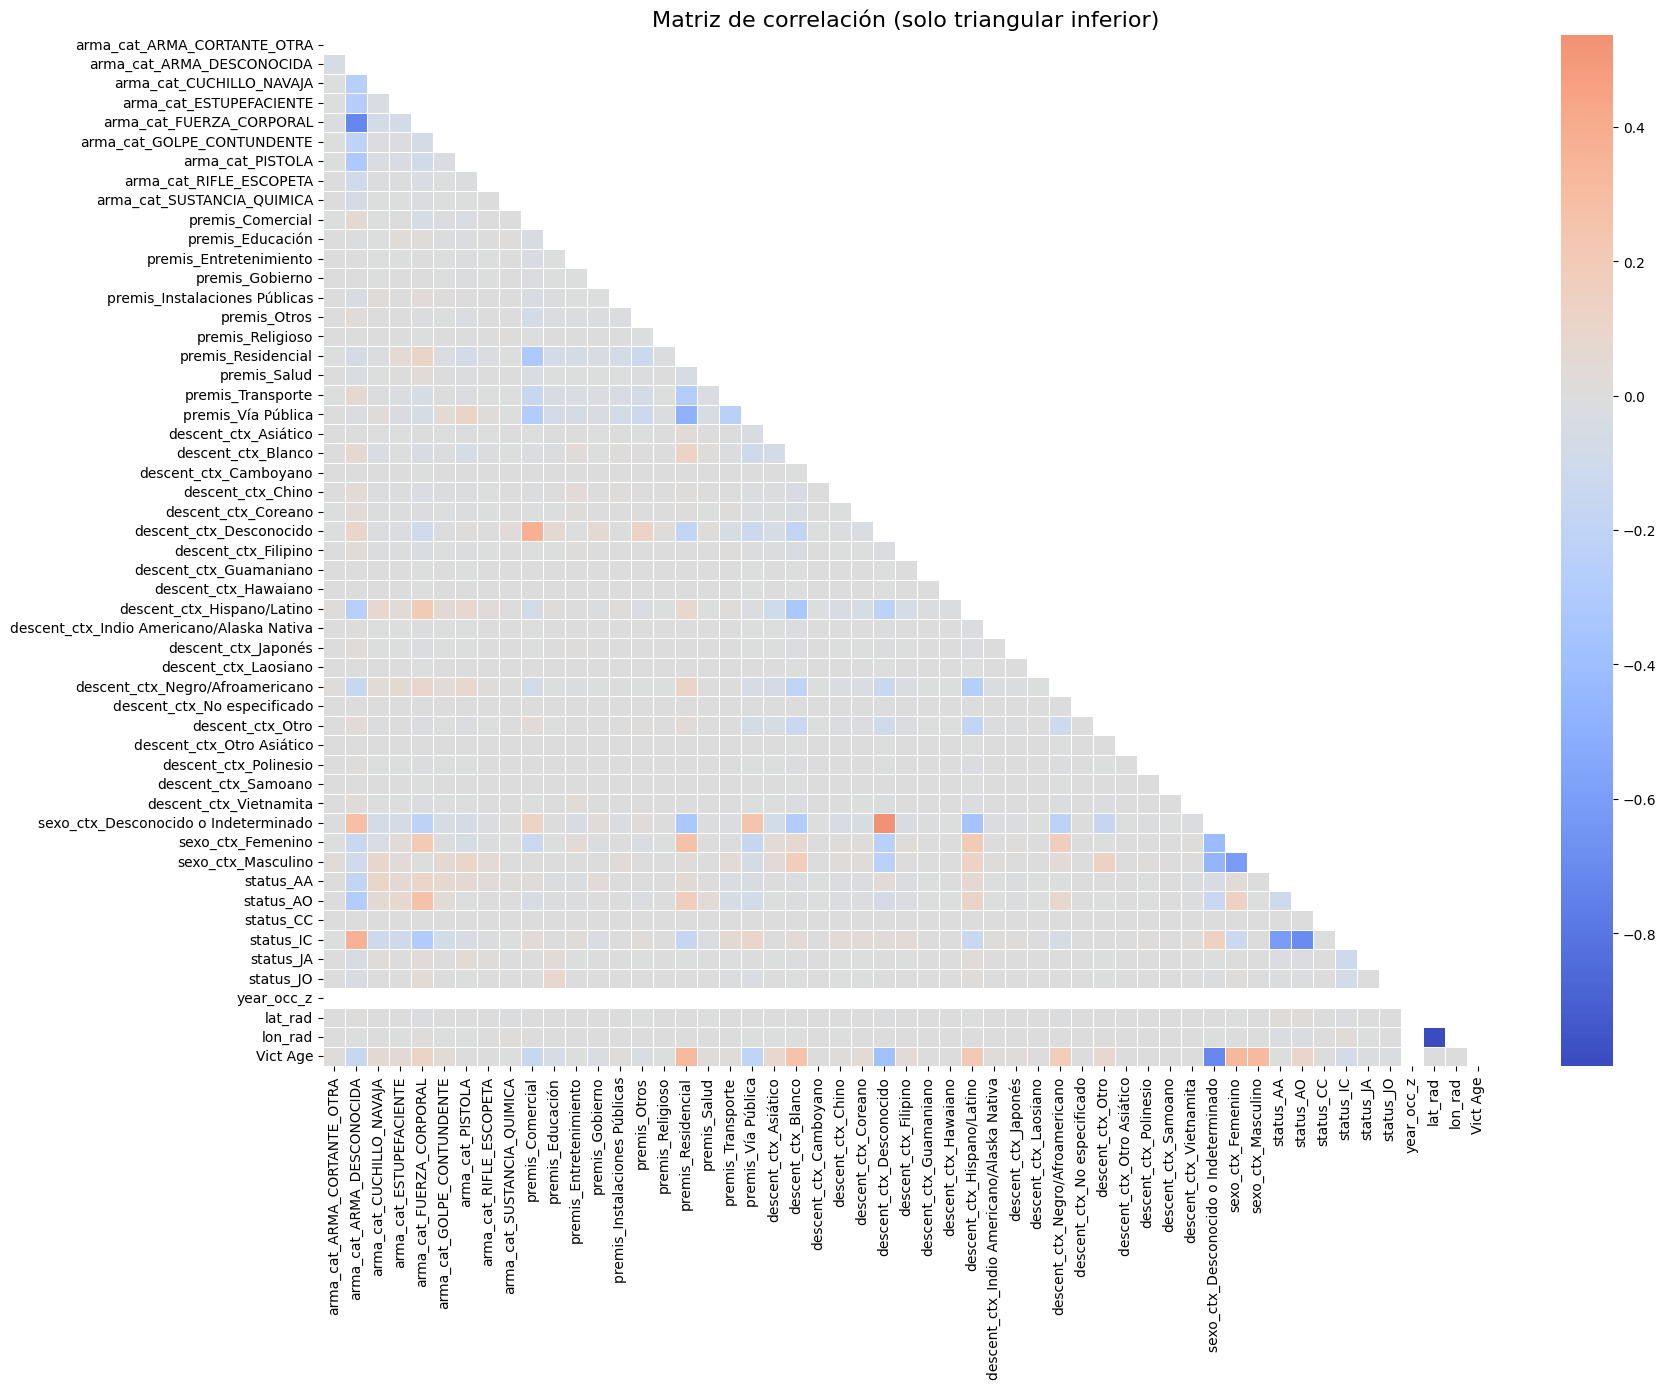

In [62]:
# Calcular la matriz de correlación
corr_matrix = X.corr()

# Crear una máscara para ocultar la parte superior
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Configurar el tamaño del gráfico
plt.figure(figsize=(18, 14))

# Dibujar el heatmap solo con la parte inferior
sns.heatmap(corr_matrix,
            mask=mask,
            cmap='coolwarm',
            center=0,
            linewidths=0.5,
            annot=False,  # True si quieres ver los valores numéricos
            fmt=".2f")

plt.title("Matriz de correlación (solo triangular inferior)", fontsize=16)
plt.tight_layout()
plt.show()

## Mas graficas

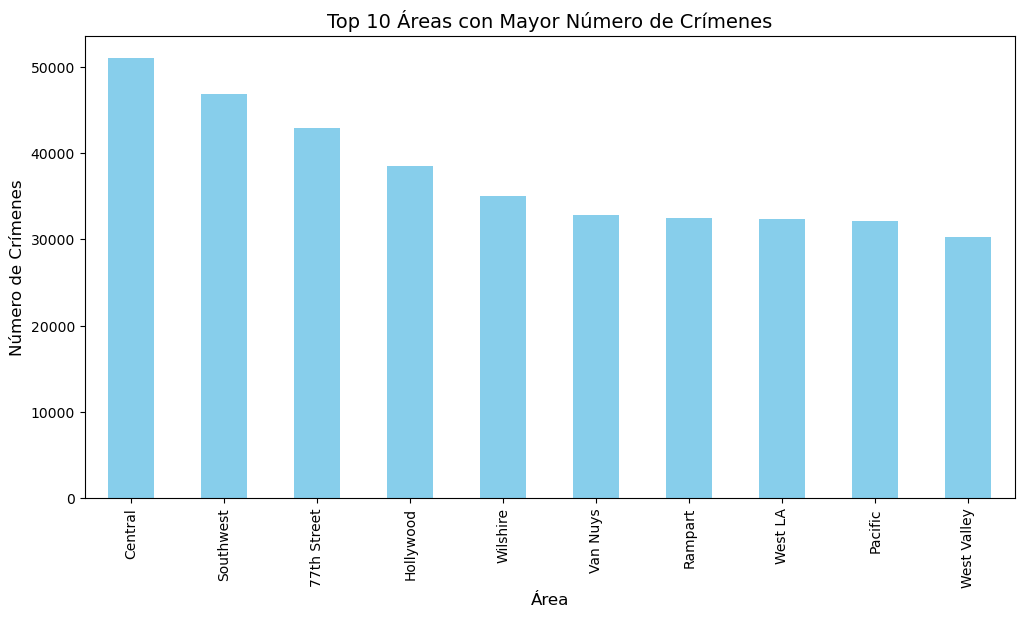

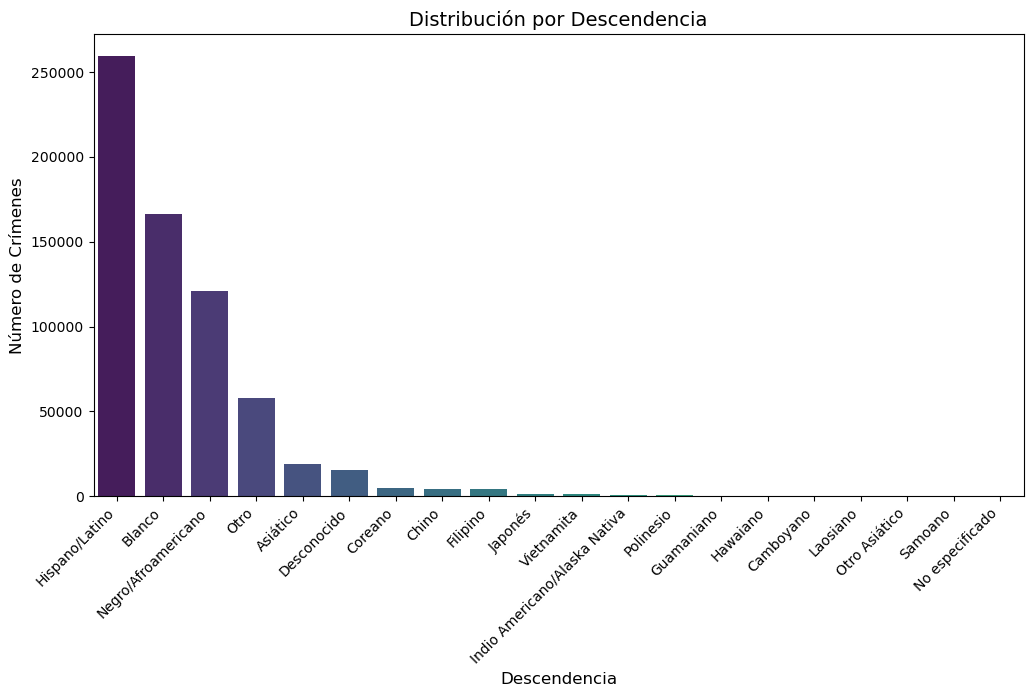

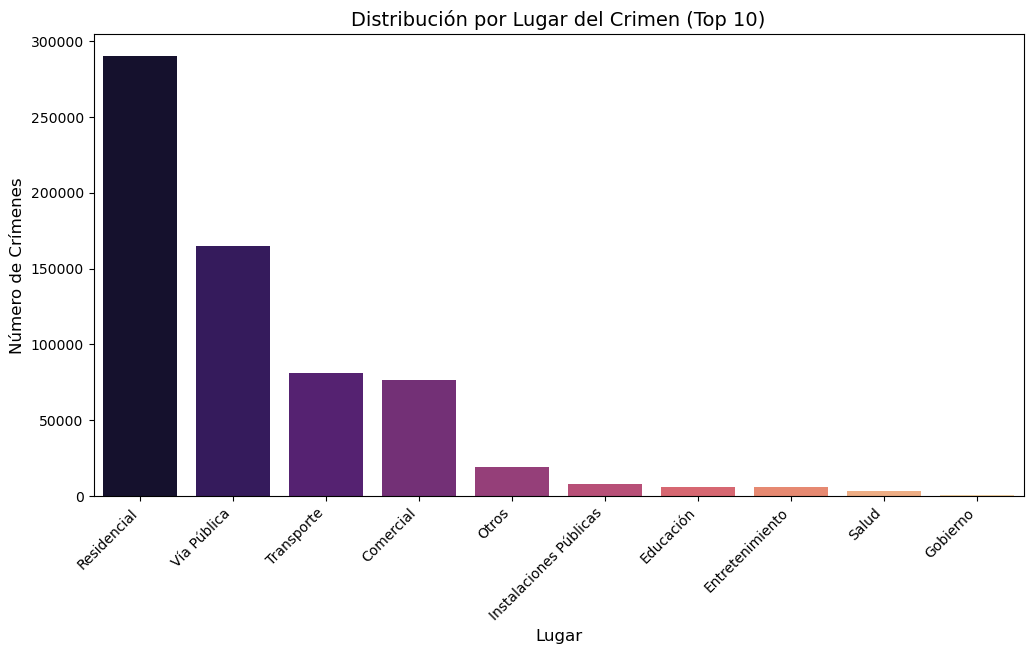

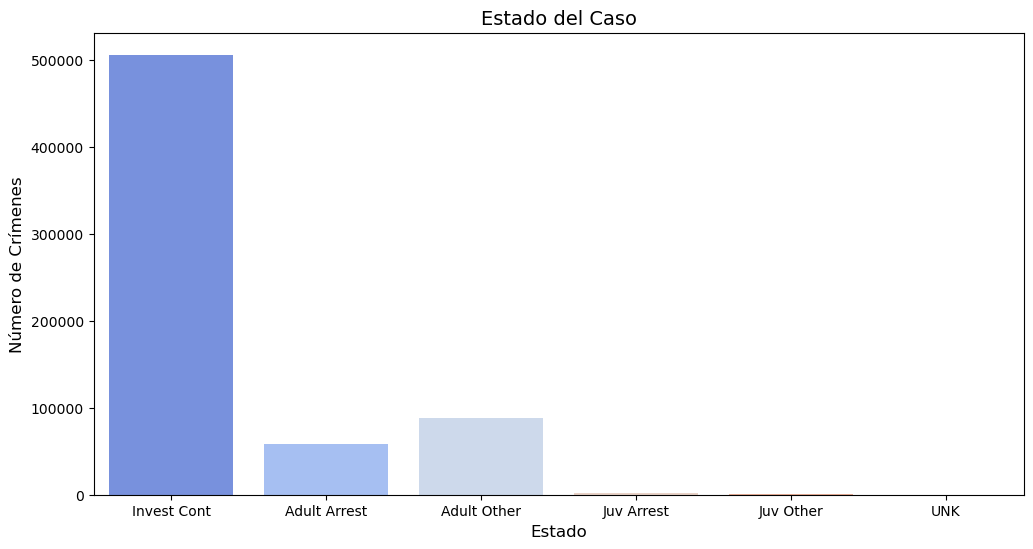

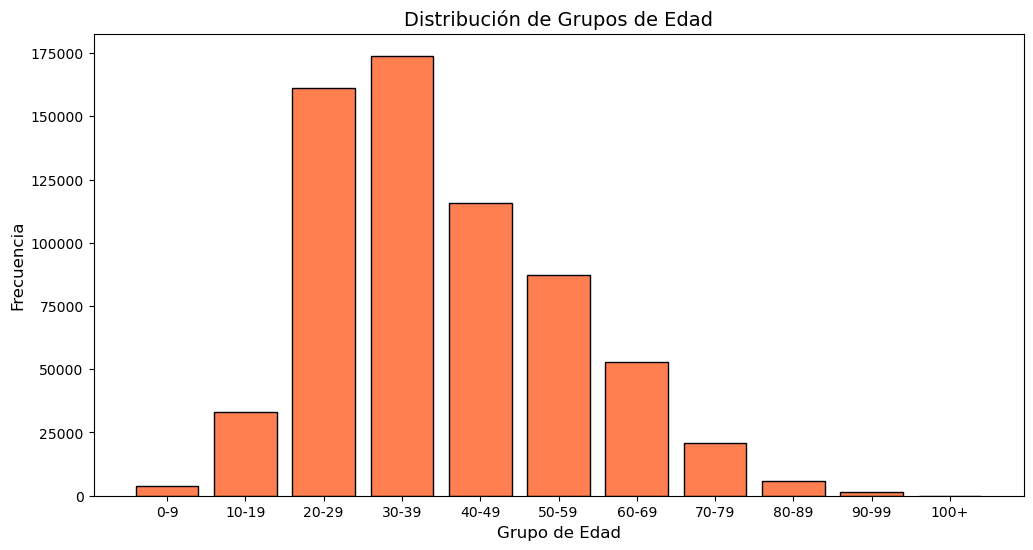

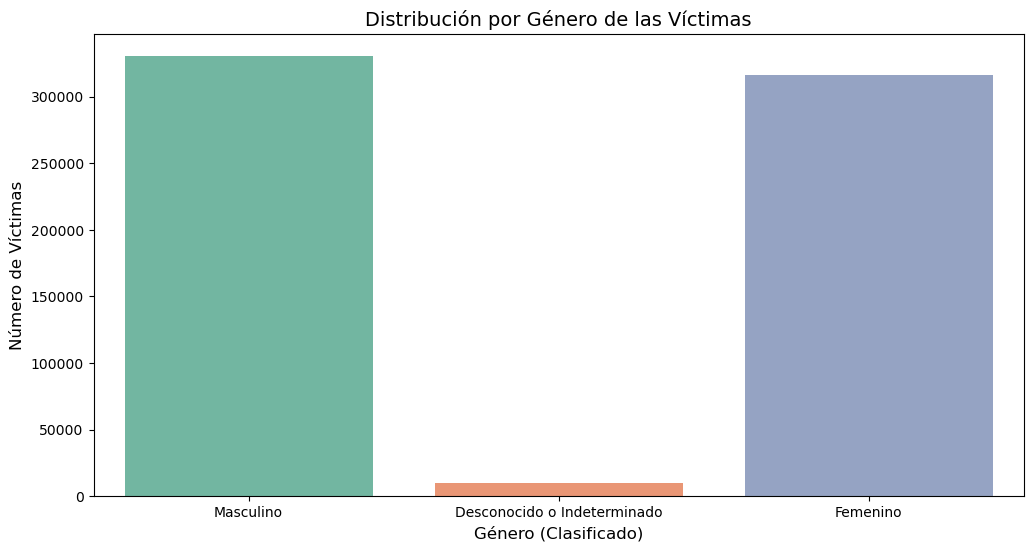

In [ ]:

# --- Distribución Geográfica de Crímenes ---
plt.figure(figsize=(12, 6))
data['AREA NAME'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Áreas con Mayor Número de Crímenes', fontsize=14)
plt.xlabel('Área', fontsize=12)
plt.ylabel('Número de Crímenes', fontsize=12)
# plt.xticks(rotation=45, ha='right')
plt.show()

# --- Análisis Demográfico ---
plt.figure(figsize=(12, 6))
sns.countplot(data=data, x='Vict Descent Clasificado_contex',
              order=data['Vict Descent Clasificado_contex'].value_counts().index, palette='viridis')
plt.title('Distribución por Descendencia', fontsize=14)
plt.xlabel('Descendencia', fontsize=12)
plt.ylabel('Número de Crímenes', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

# --- Análisis por Lugar ---
plt.figure(figsize=(12, 6))
sns.countplot(data=data, x='Premis Desc Clasificado',
              order=data['Premis Desc Clasificado'].value_counts().head(10).index, palette='magma')
plt.title('Distribución por Lugar del Crimen (Top 10)', fontsize=14)
plt.xlabel('Lugar', fontsize=12)
plt.ylabel('Número de Crímenes', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

# --- Estado del Caso ---
plt.figure(figsize=(12, 6))
sns.countplot(data=data, x='Status Desc Clasificado', palette='coolwarm')
plt.title('Estado del Caso', fontsize=14)
plt.xlabel('Estado', fontsize=12)
plt.ylabel('Número de Crímenes', fontsize=12)
# plt.xticks(rotation=45, ha='right')
plt.show()

# --- Por Edad ---
# Contar la frecuencia de cada grupo de edad
age_group_counts = data['Age Group Clasificado'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
plt.bar(age_group_counts.index, age_group_counts.values, color='coral', edgecolor='black')
plt.title('Distribución de Grupos de Edad', fontsize=14)
plt.xlabel('Grupo de Edad', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.xticks(age_group_counts.index, rotation=0)  # Opcional: ajustar etiquetas
plt.show()


# --- Por Género ---
plt.figure(figsize=(12, 6))
sns.countplot(data=data, x='Vict Sex Clasificado_contex', palette='Set2')
plt.title('Distribución por Género de las Víctimas', fontsize=14)
plt.xlabel('Género (Clasificado)', fontsize=12)
plt.ylabel('Número de Víctimas', fontsize=12)
plt.show()

1. **Zonas con más crímenes**: Las divisiones Central, Southwest y 77th registran la mayor carga delictiva. Estas áreas deben tener prioridad en recursos y patrullaje.

2. **Origen étnico de las víctimas**: La mayoría de los casos reportados involucran a personas hispanas y afroamericanas. Esto refuerza la importancia de patrullas culturalmente sensibles y equipos bilingües.

3. **Lugar del crimen**: Los crímenes ocurren mayoritariamente en zonas residenciales y vías públicas. Esto indica que las acciones preventivas deben centrarse en barrios y espacios abiertos.

4. **Estado del caso**: Más del 70 % de los casos están aún en investigación. Esto sugiere una posible sobrecarga del sistema judicial o falta de evidencia o seguimiento.

5. **Edad de las víctimas**: Los grupos de edad más afectados son de 20 a 39 años. Esto orienta las campañas de prevención hacia adultos jóvenes.

6. **Género de las víctimas**: Hay una distribución casi equilibrada entre hombres y mujeres, lo que indica que las estrategias de protección deben ser transversales y no enfocarse en un solo género.


In [ ]:
data.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Status', 'Status Desc', 'Crm Cd 1', 'LOCATION', 'LAT', 'LON',
       'Premis Desc Clasificado', 'Crm Cd Desc Clasificado',
       'Vict Sex Clasificado', 'Age Group', 'Age Group Clasificado',
       'Status Desc Clasificado', 'Vict Descent Clasificado',
       'Vict Descent Clasificado_contex', 'Vict Sex Clasificado_contex'],
      dtype='object')

In [ ]:
# Paleta de colores
primary_color = '#BF2C53'  # Rojo oscuro
secondary_color = '#F2C53D'  # Amarillo dorado
line_color = '#027373'  # Verde azulado

# Configuración del estilo
plt.style.use('default')
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'


C:\Users\User\AppData\Local\Temp\ipykernel_3532\2014579521.py:2: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



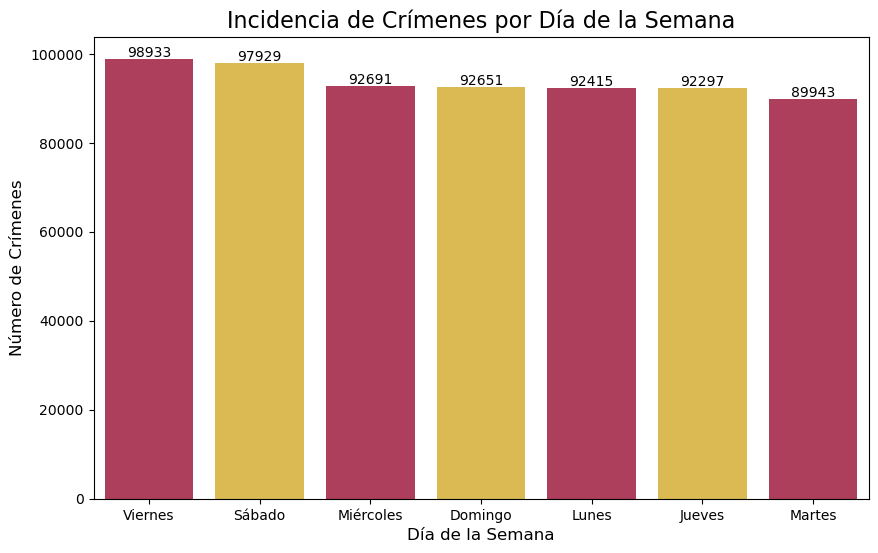

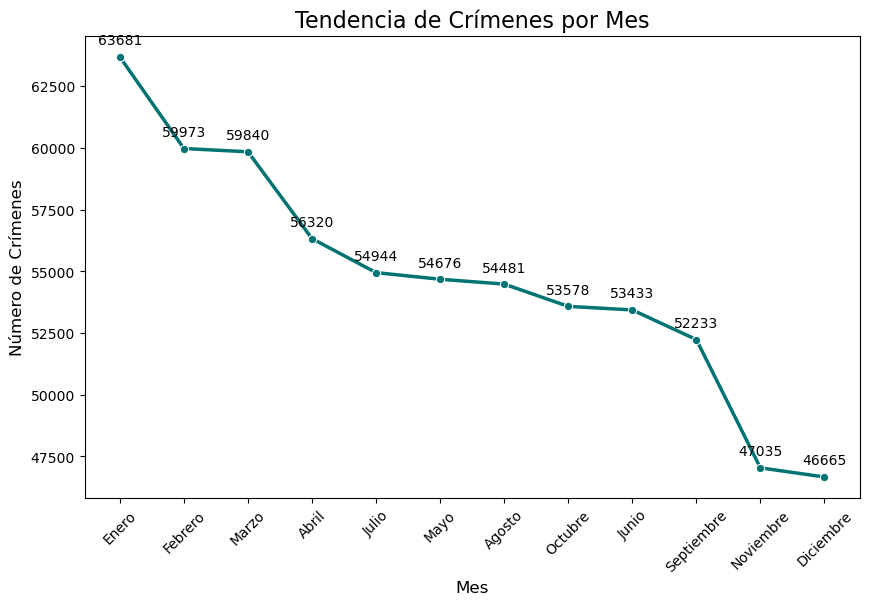

In [ ]:
# Conversión de fechas
data['DATE OCC'] = pd.to_datetime(data['DATE OCC'])

# Mapeo de días y meses al español
days_translation = {
    "Monday": "Lunes", "Tuesday": "Martes", "Wednesday": "Miércoles", 
    "Thursday": "Jueves", "Friday": "Viernes", "Saturday": "Sábado", "Sunday": "Domingo"
}
months_translation = {
    "January": "Enero", "February": "Febrero", "March": "Marzo", "April": "Abril", 
    "May": "Mayo", "June": "Junio", "July": "Julio", "August": "Agosto", 
    "September": "Septiembre", "October": "Octubre", "November": "Noviembre", "December": "Diciembre"
}

# Extraer día de la semana y mes, traducidos al español
data['Day of Week'] = data['DATE OCC'].dt.day_name().map(days_translation)
data['Month'] = data['DATE OCC'].dt.month_name().map(months_translation)

# Agrupar por día de la semana
day_group = data.groupby('Day of Week')['Crm Cd Desc Clasificado'].count().sort_values(ascending=False)

# Agrupar por mes
month_group = data.groupby('Month')['Crm Cd Desc Clasificado'].count().sort_values(ascending=False)

# Gráfico de barras - Días de la semana
plt.figure(figsize=(10, 6))
sns.barplot(x=day_group.index, y=day_group.values, palette=[primary_color, secondary_color] * len(day_group))
plt.title('Incidencia de Crímenes por Día de la Semana', fontsize=16, color='black')
plt.xlabel('Día de la Semana', fontsize=12, color='black')
plt.ylabel('Número de Crímenes', fontsize=12, color='black')

# Agregar los números encima de cada barra
for index, value in enumerate(day_group.values):
    plt.text(index, value + 500, str(value), ha='center', fontsize=10, color='black')

plt.show()

# Gráfico de líneas - Tendencia mensual
plt.figure(figsize=(10, 6))
sns.lineplot(x=month_group.index, y=month_group.values, marker='o', color=line_color, linewidth=2.5)
plt.title('Tendencia de Crímenes por Mes', fontsize=16, color='black')
plt.xlabel('Mes', fontsize=12, color='black')
plt.ylabel('Número de Crímenes', fontsize=12, color='black')
plt.xticks(rotation=45)

# Agregar los números encima de cada punto
for x, y in zip(month_group.index, month_group.values):
    plt.text(x, y + 500, str(y), ha='center', fontsize=10, color='black')

plt.show()

1. **Incidencia por día de la semana**: Los crímenes aumentan notablemente los viernes y sábados, superando los 97,000 incidentes por día. Esto sugiere que los fines de semana requieren refuerzos especiales en patrullaje, sobre todo en la noche.

2. **Tendencia mensual**: Enero concentra el mayor número de crímenes del año, con un descenso progresivo hacia diciembre. Las primeras semanas del año deberían tener operativos especiales, especialmente cuando se combina con la reducción de personal por vacaciones.


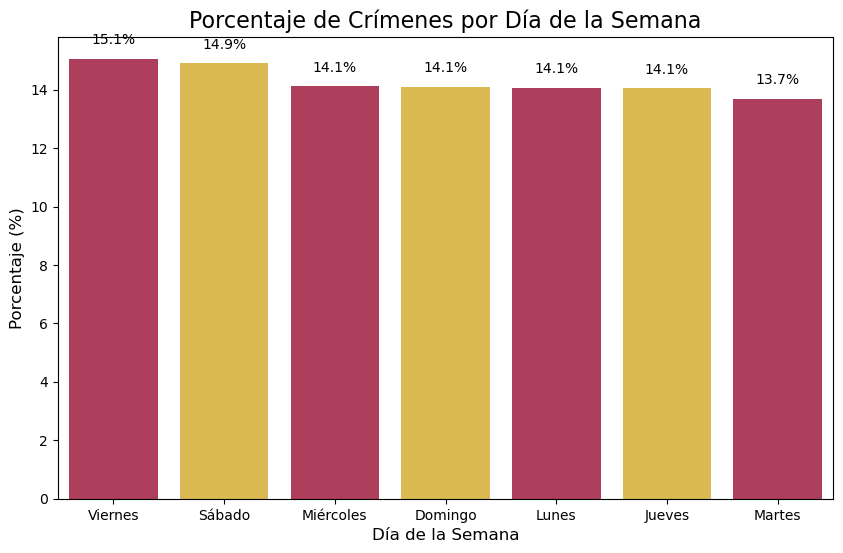

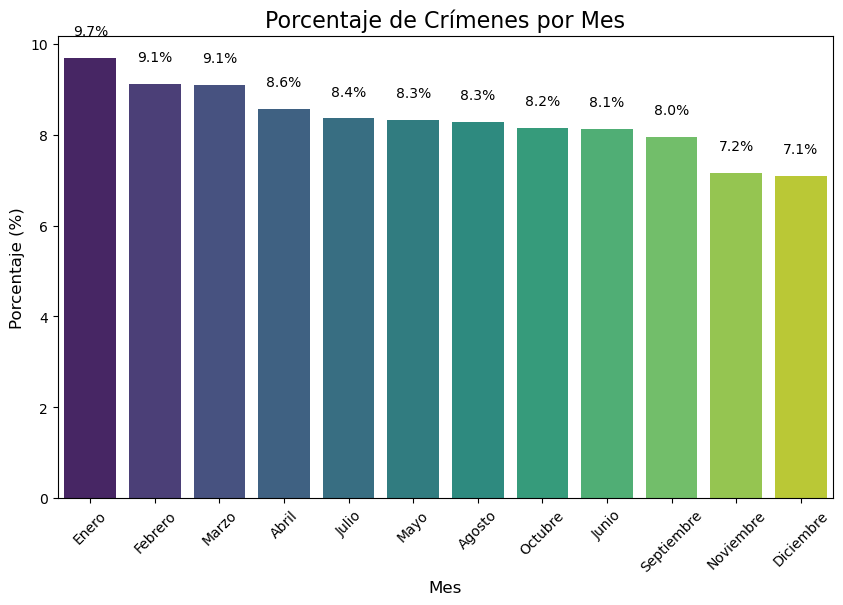

In [ ]:
# Calcular los porcentajes para días de la semana
day_group_percent = (day_group / day_group.sum()) * 100

# Gráfico de barras - Porcentaje por Día de la Semana
plt.figure(figsize=(10, 6))
sns.barplot(x=day_group_percent.index, y=day_group_percent.values, palette=[primary_color, secondary_color] * len(day_group))
plt.title('Porcentaje de Crímenes por Día de la Semana', fontsize=16, color='black')
plt.xlabel('Día de la Semana', fontsize=12, color='black')
plt.ylabel('Porcentaje (%)', fontsize=12, color='black')

# Agregar los valores porcentuales encima de cada barra
for index, value in enumerate(day_group_percent.values):
    plt.text(index, value + 0.5, f'{value:.1f}%', ha='center', fontsize=10, color='black')

plt.show()

# Calcular los porcentajes para los meses
month_group_percent = (month_group / month_group.sum()) * 100

# Gráfico de barras - Porcentaje por Mes
plt.figure(figsize=(10, 6))
sns.barplot(x=month_group_percent.index, y=month_group_percent.values, palette=sns.color_palette('viridis', len(month_group)))
plt.title('Porcentaje de Crímenes por Mes', fontsize=16, color='black')
plt.xlabel('Mes', fontsize=12, color='black')
plt.ylabel('Porcentaje (%)', fontsize=12, color='black')

# Agregar los valores porcentuales encima de cada barra
for index, value in enumerate(month_group_percent.values):
    plt.text(index, value + 0.5, f'{value:.1f}%', ha='center', fontsize=10, color='black')

plt.xticks(rotation=45)
plt.show()




1. **Porcentaje de crímenes por día**: Los viernes (15.1 %) y sábados (14.9 %) concentran la mayor proporción de crímenes semanales. Esto confirma que el fin de semana necesita refuerzos operativos, sobre todo en horarios nocturnos.

2. **Porcentaje por mes**: Enero destaca como el mes más crítico con casi el 10 % de los delitos del año, seguido por febrero y marzo. A medida que avanza el año, la proporción baja. Esto sugiere que los planes de seguridad deben reforzarse especialmente durante el primer trimestre.


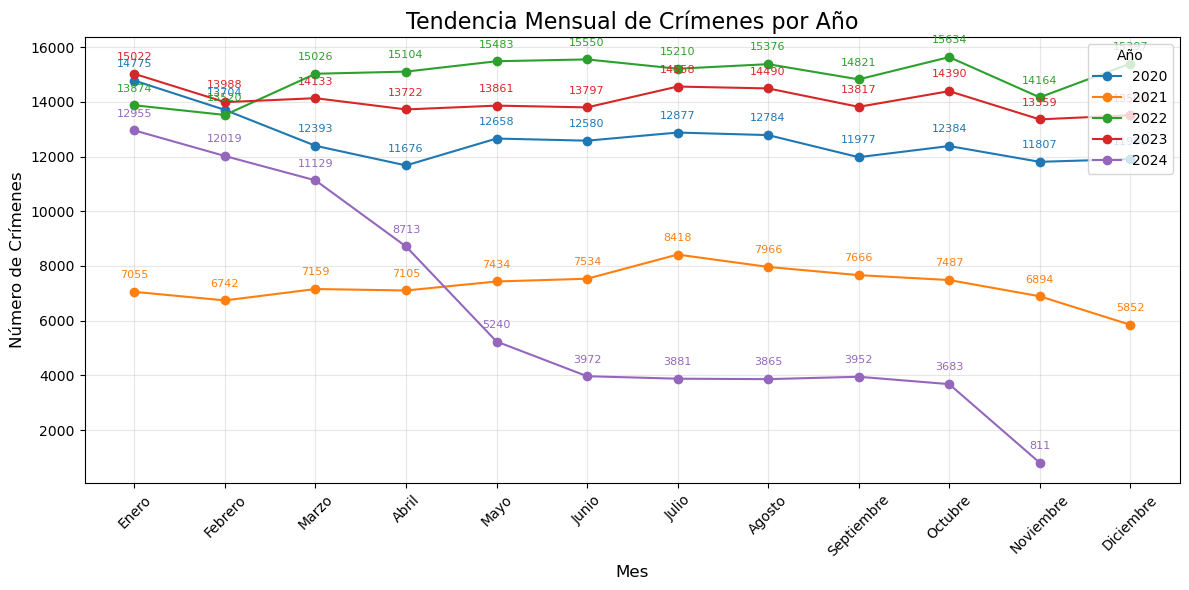

In [ ]:
# Crear una columna de año
data['Year'] = data['DATE OCC'].dt.year

# Traducir nombres de meses al español
month_translation = {
    'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril', 'May': 'Mayo', 'June': 'Junio',
    'July': 'Julio', 'August': 'Agosto', 'September': 'Septiembre', 'October': 'Octubre',
    'November': 'Noviembre', 'December': 'Diciembre'
}

data['Month'] = data['DATE OCC'].dt.month_name().map(month_translation)

# Agrupar por año y mes
monthly_trends = data.groupby([data['Year'], data['Month']])['Crm Cd Desc Clasificado'].count().reset_index()

# Ordenar los meses en español
monthly_trends['Month'] = pd.Categorical(
    monthly_trends['Month'],
    categories=['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
                'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'],
    ordered=True
)

# Pivotear para usar en el gráfico de líneas
monthly_trends_pivot = monthly_trends.pivot(index='Month', columns='Year', values='Crm Cd Desc Clasificado')

# Gráfico de líneas
plt.figure(figsize=(12, 6))
colors = sns.color_palette("tab10", len(monthly_trends_pivot.columns))

for year, color in zip(monthly_trends_pivot.columns, colors):
    plt.plot(monthly_trends_pivot.index, monthly_trends_pivot[year], marker='o', label=str(year), color=color)

plt.title('Tendencia Mensual de Crímenes por Año', fontsize=16, color='black')
plt.xlabel('Mes', fontsize=12, color='black')
plt.ylabel('Número de Crímenes', fontsize=12, color='black')
plt.xticks(rotation=45)
plt.legend(title='Año', loc='upper right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()

# Mostrar los valores sobre cada punto
for i, year in enumerate(monthly_trends_pivot.columns):
    for x, y in zip(monthly_trends_pivot.index, monthly_trends_pivot[year]):
        if not pd.isna(y):
            plt.text(x, y + 500, f'{int(y)}', ha='center', fontsize=8, color=colors[i])

plt.show()


Esta gráfica muestra que **el primer trimestre del año tiende a tener más crímenes**, especialmente en enero, para casi todos los años analizados (2020–2023). En contraste, el año 2024 muestra un **descenso drástico y sostenido**, lo cual puede deberse a falta de registros completos o a cambios operativos recientes.

Esto sugiere que **las primeras semanas del año deben tener refuerzo especial**, con patrullaje preventivo y operativos visibles. Además, es importante validar los datos de 2024 antes de asumir que la baja es real.

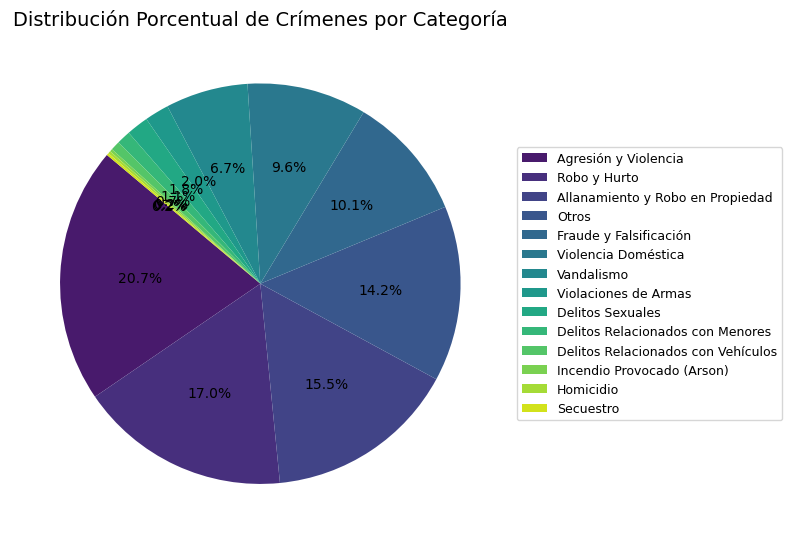

In [ ]:
# Calcular la frecuencia de crímenes por categoría
crime_frequency = data['Crm Cd Desc Clasificado'].value_counts()

# Calcular el porcentaje de cada categoría
crime_percent = (crime_frequency / crime_frequency.sum()) * 100

# Configuración del tamaño de la figura
plt.figure(figsize=(8, 8))

# Crear el gráfico de pastel con una paleta de colores adecuada
patches, texts, autotexts = plt.pie(
    crime_percent,  # Datos de porcentaje de crímenes
    startangle=140,  # Ángulo inicial para el gráfico
    colors=sns.color_palette('viridis', len(crime_frequency)),  # Paleta de colores para las categorías
    autopct='%1.1f%%'  # Mostrar porcentajes con 1 decimal
)

# Título del gráfico
plt.title('Distribución Porcentual de Crímenes por Categoría', fontsize=14, color='black')

# Añadir una leyenda fuera del gráfico para facilitar la lectura
plt.legend(
    patches,  # Elementos del gráfico
    crime_frequency.index,  # Nombres de las categorías
    loc='center left',  # Posición de la leyenda
    bbox_to_anchor=(1, 0.5),  # Ubicación fuera del gráfico
    fontsize=9  # Tamaño de la fuente de la leyenda
)

# Ajustar el diseño para evitar superposiciones
plt.tight_layout()

# Mostrar el gráfico
plt.show()


La categoría más común de crimen en Los Ángeles es la **agresión y violencia** (20.7 %), seguida por **robo y hurto** (17 %) y **allanamiento o robo en propiedad** (15.5 %). Esto indica que la mayoría de los delitos tienen un componente directo de confrontación o pérdida patrimonial.

Los delitos graves pero menos frecuentes como **homicidio, secuestro o incendios provocados** representan una fracción muy pequeña. Por tanto, las estrategias deben enfocarse en **prevenir la violencia física y proteger la propiedad**, sin descuidar la vigilancia especializada para delitos más complejos.


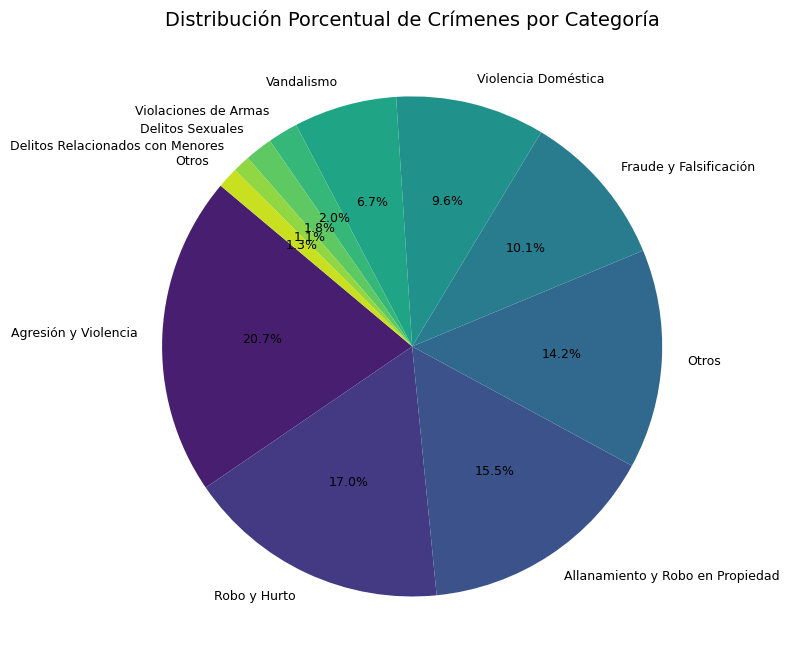

In [ ]:
# Establecer un umbral para agrupar categorías
threshold = 1  # Por ejemplo, agrupar categorías con menos del 1%

# Crear un DataFrame temporal
crime_data = pd.DataFrame({
    'Categoría': crime_frequency.index,
    'Frecuencia': crime_frequency.values,
    'Porcentaje': crime_percent.values
})

# Separar categorías principales y otras
main_categories = crime_data[crime_data['Porcentaje'] >= threshold]
other_categories = crime_data[crime_data['Porcentaje'] < threshold]

# Sumar las categorías "Otros"
others = pd.DataFrame({
    'Categoría': ['Otros'],
    'Frecuencia': [other_categories['Frecuencia'].sum()],
    'Porcentaje': [other_categories['Porcentaje'].sum()]
})

# Combinar categorías principales con "Otros"
crime_data_final = pd.concat([main_categories, others], ignore_index=True)

# Gráfico de pastel con categorías agrupadas
plt.figure(figsize=(8, 8))

patches, texts, autotexts = plt.pie(
    crime_data_final['Porcentaje'],
    labels=crime_data_final['Categoría'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('viridis', len(crime_data_final))
)

plt.title('Distribución Porcentual de Crímenes por Categoría', fontsize=14)

# Ajustar tamaño de fuente
for text in texts + autotexts:
    text.set_fontsize(9)

plt.tight_layout()

plt.show()


La distribución confirma que **más de la mitad de los crímenes en Los Ángeles** corresponden a tres categorías: **agresión y violencia, robo y hurto, y allanamiento a propiedad**. Esto sugiere que los recursos policiales deberían concentrarse en **patrullajes preventivos en zonas residenciales y comerciales**, donde estos delitos son más frecuentes.

Por otro lado, delitos como **violaciones de armas, delitos sexuales o contra menores** aunque menos comunes, requieren protocolos específicos por su gravedad. Estos deben ser atendidos por **unidades especializadas** con enfoque sensible y capacitación constante.


C:\Users\User\AppData\Local\Temp\ipykernel_3532\1511299163.py:21: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_3532\1511299163.py:24: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

c:\Users\User\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

c:\Users\User\anaconda3\L

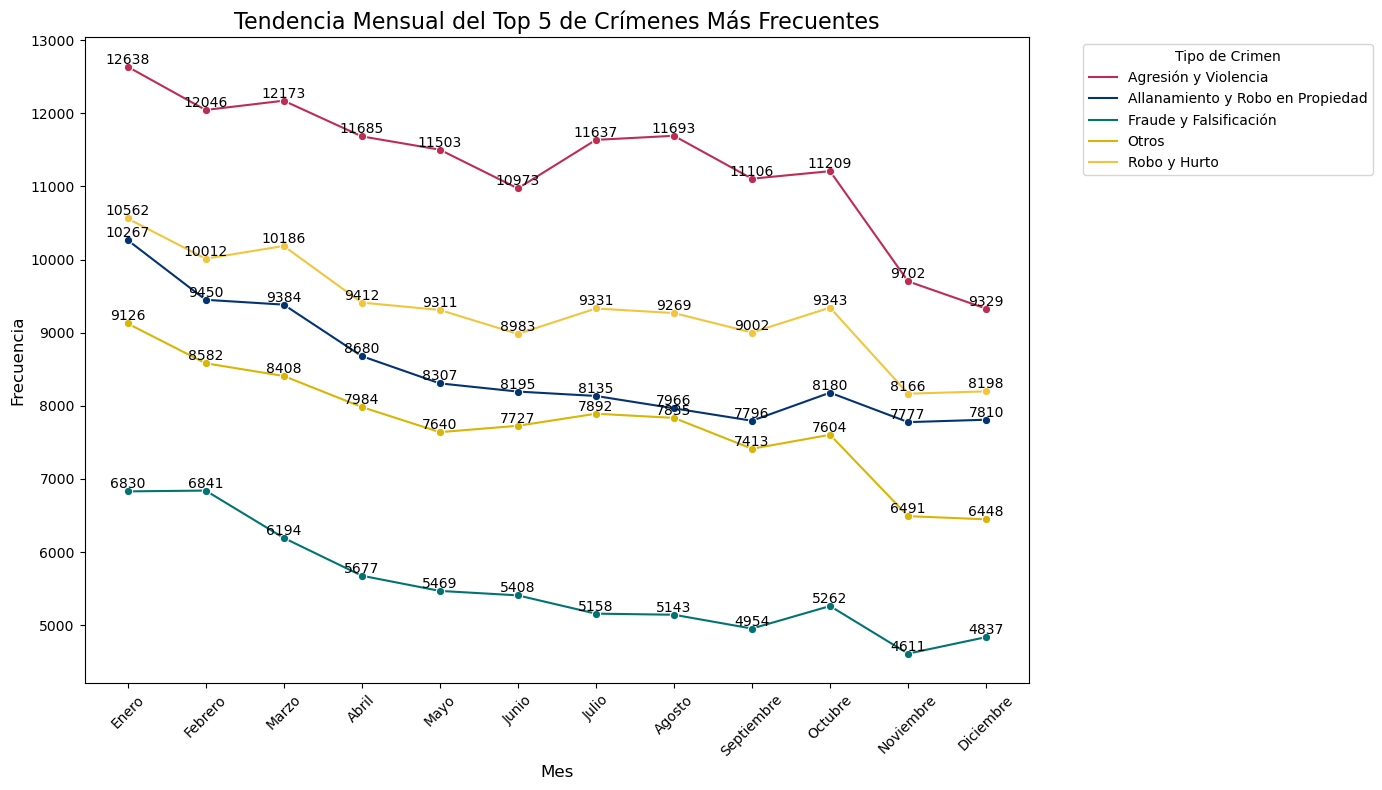

In [ ]:
# Extraer el mes de la columna 'DATE OCC'
data['Month'] = data['DATE OCC'].dt.month_name()

# Agrupar por mes y tipo de crimen, y contar las frecuencias
crime_monthly = data.groupby(['Month', 'Crm Cd Desc Clasificado']).size().reset_index(name='Frequency')

# Seleccionar el top 5 crímenes más frecuentes a nivel global
top_5_crimes = crime_monthly.groupby('Crm Cd Desc Clasificado')['Frequency'].sum().nlargest(5).index

# Filtrar los datos para incluir solo el top 5 crímenes
filtered_data = crime_monthly[crime_monthly['Crm Cd Desc Clasificado'].isin(top_5_crimes)]

# Diccionario para traducir los nombres de los meses
month_translation = {
    "January": "Enero", "February": "Febrero", "March": "Marzo", "April": "Abril",
    "May": "Mayo", "June": "Junio", "July": "Julio", "August": "Agosto",
    "September": "Septiembre", "October": "Octubre", "November": "Noviembre", "December": "Diciembre"
}

# Aplicar traducción a la columna 'Month' en el dataframe
filtered_data['Month'] = filtered_data['Month'].map(month_translation)

# Ordenar los meses traducidos cronológicamente
filtered_data['Month'] = pd.Categorical(
    filtered_data['Month'], 
    categories=[
        "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
        "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"
    ], 
    ordered=True
)

# Definir los colores para las líneas del gráfico
colors = ["#BF2C53", "#023373", "#027373", "#D9B504", "#F2C53D"]

# Crear el gráfico de líneas
plt.figure(figsize=(14, 8))
lineplot = sns.lineplot(
    x='Month', 
    y='Frequency', 
    hue='Crm Cd Desc Clasificado', 
    data=filtered_data, 
    marker='o', 
    palette=colors  # Usamos los colores definidos
)

# Títulos y etiquetas
plt.title('Tendencia Mensual del Top 5 de Crímenes Más Frecuentes', fontsize=16, color='black')
plt.xlabel('Mes', fontsize=12, color='black')
plt.ylabel('Frecuencia', fontsize=12, color='black')
plt.xticks(rotation=45)
plt.legend(title='Tipo de Crimen', bbox_to_anchor=(1.05, 1), loc='upper left')

# Agregar etiquetas de valores en los puntos
for line in lineplot.get_lines():
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        plt.text(x, y, f'{int(y)}', color='black', fontsize=10, ha='center', va='bottom')

# Mostrar el gráfico
plt.tight_layout()
plt.show()




El gráfico muestra que **la agresión y violencia lidera consistentemente todos los meses del año**, con un leve descenso hacia fin de año. **Robo y hurto, así como allanamientos**, también son constantes, pero disminuyen progresivamente desde enero. Esto indica que los primeros tres meses concentran la mayor carga operativa, por lo que se recomienda **reforzar la presencia policial durante ese periodo**.

También se observa que **la actividad delictiva baja visiblemente en noviembre y diciembre**, lo cual sugiere que es posible **reubicar recursos en esos meses hacia tareas de prevención o entrenamiento sin afectar la cobertura básica**.
